In [3]:
# COMMIT 1: Project Setup and Dataset Exploration
# Implementation Scope:
# - Central configuration, global seeding and automatic device selection.
# - Zip-based image archive that reads train and test images without extracting them.
# - Label distribution, class imbalance ratio, image integrity and dimension profiling.
# - Correlation heatmap, file-size scatter plot and per-class sample grid.
# - Per-device batch sizes (CUDA / Apple Silicon / CPU), output folders and a safe extraction of
#   results.tar.gz that restores only saved_results/ so a Mac can reload the trained checkpoints.

# importing standard libraries
import fcntl
import gc
import io
import math
import os
import random
import sys
import tarfile
import threading
import time
import zipfile
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path, PurePosixPath

# letting MPS ops without a native kernel fall back to the CPU (must be set before torch is imported)
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")

# importing third-party libraries
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from sklearn.model_selection import StratifiedGroupKFold
from torchvision import models

# setting up the configuration dictionary with paths, model settings and hyperparameters
CONFIG = {
    "labels_csv": Path("./train_labels.csv"),
    "train_archives": (Path("./train_part1.zip"), Path("./train_part2.zip")),
    "test_archives": (Path("./test.zip"),),
    "cache_dir": Path("./outputs/cache"),  # uint8 pixel caches built from the zip archives
    "history_dir": Path("./saved_results/history"),  # per-run training history CSVs
    "checkpoint_dir": Path("./saved_results/checkpoints"),  # best-validation-loss weights per run
    "sample_submission_csv": Path("./sample_submission.csv"),
    "submission_path": Path("./submission.csv"),
    "retrain": False,  # True forces training even when a saved run exists
    "write_first_submission": False,  # the first fine-tune is not the submitted model, so its test pass is skipped
    "prediction_dir": Path("./saved_results/predictions"),  # saved probabilities, reused instead of re-running inference
    "letterbox_mode": "reflect",  # padding used when letterboxing; "reflect" mirrors the image border
    "unfreeze_from": 6,  # first ConvNeXt feature block that is unfrozen during fine-tuning
    "finetune_head_lr": 1e-4,  # learning rate of the classification head while fine-tuning
    "finetune_backbone_lr": 1e-5,  # much lower learning rate for the unfrozen backbone blocks
    "image_size": (224, 224),  # (height, width) every image is resized to
    "image_extensions": {".jpg", ".jpeg", ".png"},
    "classes": (
        "CatEye", "DogEye", "CatFace", "DogFace",
        "CatMouth", "DogMouth", "CatNose", "DogNose",
    ),
    "imagenet_mean": (0.485, 0.456, 0.406),  # per-channel mean used to normalise images (ImageNet statistics)
    "imagenet_std": (0.229, 0.224, 0.225),  # per-channel standard deviation used to normalise images
    "seed": 42,
    "val_fraction": 0.2,  # fraction of the training data held out for validation
    "profile_sample_size": 3000,  # number of images sampled when profiling sizes and corrupted files
    "batch_size": 64,  # batch size of the structural forward-pass check (training uses the per-device sizes below)
    "weight_decay": 1e-2,  # weight decay factor of the AdamW optimizer
    "eta_min": 1e-6,  # minimum learning rate of the cosine annealing scheduler
    "dropout": 0.4,  # dropout rate in the baseline CNN
    "head_dropout": 0.3,  # dropout rate before the transfer model's linear head
    "backbone": "convnext_tiny",  # torchvision backbone used for transfer learning
    "device": torch.device(
        "cuda" if torch.cuda.is_available()
        else "mps" if torch.backends.mps.is_available()
        else "cpu"
    ),
}
# deriving the number of classes and a class-name to index lookup from the "classes" tuple
CONFIG["num_classes"] = len(CONFIG["classes"])
class_to_idx = {name: idx for idx, name in enumerate(CONFIG["classes"])}


# defining a helper that seeds every random number generator used in the notebook
def seed_everything(seed):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


# seeding all generators and applying the plotting theme
seed_everything(CONFIG["seed"])
sns.set_theme(style="whitegrid", context="notebook")
print(f"seed={CONFIG['seed']} | device={CONFIG['device']} | target size={CONFIG['image_size']}")

# choosing batch sizes per device so an 8 GB Mac never inherits the CUDA values
CONFIG["train_batch_size"] = {"cuda": 256, "mps": 32, "cpu": 16}[CONFIG["device"].type]
CONFIG["eval_batch_size"] = {"cuda": 1024, "mps": 64, "cpu": 64}[CONFIG["device"].type]
# allowing training only on CUDA; other devices reload the saved checkpoints
CONFIG["allow_local_training"] = CONFIG["device"].type == "cuda"
# selecting which model writes submission.csv in the last cell: "aspect", "reframe" or "ensemble"
CONFIG["final_submission"] = "aspect"

# creating the output folders if they do not exist yet
for key in ("cache_dir", "history_dir", "checkpoint_dir", "prediction_dir"):
    CONFIG[key].mkdir(parents=True, exist_ok=True)

# restoring saved histories and checkpoints, extracting only saved_results/ so the notebook copy inside the archive is left alone
results_archive = Path("./results.tar.gz")
if results_archive.exists() and not any(CONFIG["checkpoint_dir"].glob("*.pt")):
    with tarfile.open(results_archive) as tar:
        wanted = [m for m in tar.getmembers()
                  if m.name.removeprefix("./").startswith("saved_results/") and ".ipynb_checkpoints" not in m.name]
        tar.extractall(".", members=wanted)

print(f"device={CONFIG['device']} | train batch={CONFIG['train_batch_size']} | "
      f"eval batch={CONFIG['eval_batch_size']} | local training allowed={CONFIG['allow_local_training']}")


seed=42 | device=mps | target size=(224, 224)
device=mps | train batch=32 | eval batch=64 | local training allowed=False


In [4]:
# defining the ImageArchive class to read images straight from zip archives
class ImageArchive:
    """Index images inside zip files and decode them on demand, without extracting anything."""

    def __init__(self, zip_paths, extensions):
        self.zip_paths = tuple(Path(p) for p in zip_paths)
        self.extensions = frozenset(e.lower() for e in extensions)
        self.members = {}
        for zip_path in self.zip_paths:
            with zipfile.ZipFile(zip_path) as archive:
                for info in archive.infolist():
                    member = PurePosixPath(info.filename)
                    # skipping folders, macOS metadata files and anything that is not an image
                    is_junk = info.is_dir() or member.parts[0] == "__MACOSX" or member.name.startswith("._")
                    if is_junk or member.suffix.lower() not in self.extensions:
                        continue
                    # image ids come from file names, so a repeated name would silently overwrite an image
                    if member.stem in self.members:
                        raise ValueError(f"duplicate image id {member.stem} in {zip_path}")
                    self.members[member.stem] = (zip_path, info.filename, info.CRC, info.file_size)
        self.ids = sorted(self.members)
        self._local = threading.local()

    # returning the number of unique image ids
    def __len__(self):
        return len(self.members)

    # checking whether an image id exists in the archive
    def __contains__(self, image_id):
        return image_id in self.members

    # returning an open ZipFile per thread, because zip handles are not thread safe
    def _handle(self, zip_path):
        files = getattr(self._local, "files", None)
        if files is None:
            files = self._local.files = {}
        if zip_path not in files:
            files[zip_path] = zipfile.ZipFile(zip_path)
        return files[zip_path]

    # reading the raw bytes of an image given its id
    def read_bytes(self, image_id):
        zip_path, name, _, _ = self.members[image_id]
        return self._handle(zip_path).read(name)

    # decoding an image into RGB format given its id
    def open_rgb(self, image_id):
        with Image.open(io.BytesIO(self.read_bytes(image_id))) as img:
            return img.convert("RGB")

    # returning the stored file size of an image given its id
    def file_size(self, image_id):
        return self.members[image_id][3]

    # returning a content digest (CRC and file size) that identifies duplicate images
    def digest(self, image_id):
        _, _, crc, size = self.members[image_id]
        return f"{crc:08x}-{size}"


# indexing the training and test archives
train_archive = ImageArchive(CONFIG["train_archives"], CONFIG["image_extensions"])
test_archive = ImageArchive(CONFIG["test_archives"], CONFIG["image_extensions"])
print(f"train archive: {len(train_archive):,} images | test archive: {len(test_archive):,} images")


train archive: 63,660 images | test archive: 29,443 images


Total labelled samples: 63,660

          count  percent
class                   
CatEye    13884    21.81
DogEye    11580    18.19
CatFace    6942    10.90
DogFace    5790     9.10
CatMouth   6942    10.90
DogMouth   5790     9.10
CatNose    6942    10.90
DogNose    5790     9.10

Imbalance ratio (majority/minority): 2.398:1 (CatEye = 13,884, DogFace = 5,790)


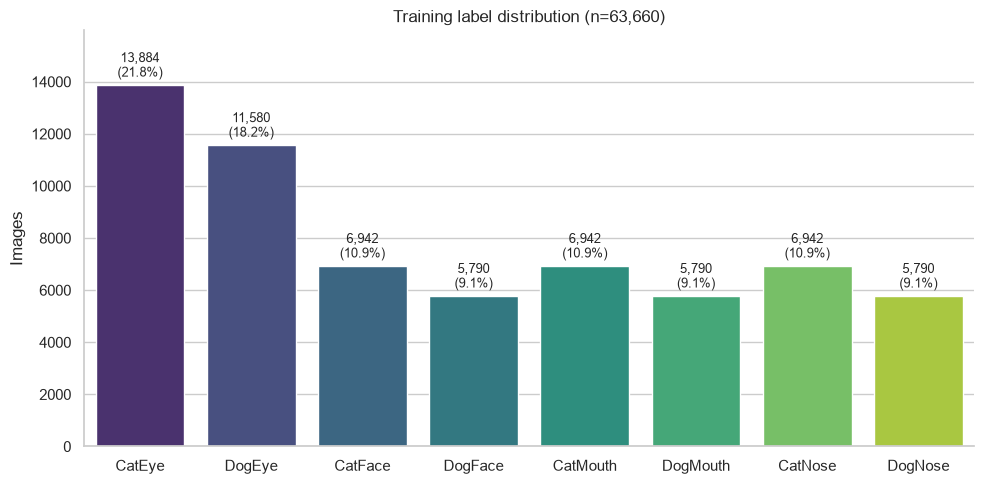

In [5]:
# reading the labels CSV into a DataFrame, keeping image ids as strings
labels = pd.read_csv(CONFIG["labels_csv"], dtype={"image_id": str})
classes = CONFIG["classes"]

# validating the labels: only known classes, unique image ids and no missing values
unexpected = set(labels["class"]) - set(classes)
assert not unexpected, f"Unexpected labels: {sorted(unexpected)}"
assert labels["image_id"].is_unique, "Duplicate image_id values in labels"
assert labels["class"].notna().all(), "Null labels present"

# counting images per class and converting the counts to percentages
distribution = labels["class"].value_counts().reindex(classes).rename("count").to_frame()
distribution["percent"] = distribution["count"] / distribution["count"].sum() * 100

print(f"Total labelled samples: {len(labels):,}\n")
print(distribution.assign(percent=distribution["percent"].round(2)).to_string())
# comparing the largest and smallest classes to quantify the class imbalance
majority_class, minority_class = distribution["count"].idxmax(), distribution["count"].idxmin()
imbalance_ratio = distribution["count"].max() / distribution["count"].min()
print(f"\nImbalance ratio (majority/minority): {imbalance_ratio:.3f}:1 "
      f"({majority_class} = {distribution['count'].max():,}, {minority_class} = {distribution['count'].min():,})")

# plotting the class distribution as a bar chart
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(
    data=distribution.reset_index(names="class"),
    x="class", y="count", hue="class", order=classes,
    palette="viridis", legend=False, ax=ax,
)
# annotating each bar with its count and percentage
for position, (_, row) in enumerate(distribution.iterrows()):
    ax.annotate(
        f"{int(row['count']):,}\n({row['percent']:.1f}%)",
        (position, row["count"]), xytext=(0, 3), textcoords="offset points",
        ha="center", va="bottom", fontsize=9,
    )

# adding headroom above the tallest bar for the annotations, then setting labels and title
ax.set_ylim(0, distribution["count"].max() * 1.15)
ax.set_xlabel("")
ax.set_ylabel("Images")
ax.set_title(f"Training label distribution (n={len(labels):,})")
sns.despine(ax=ax)
fig.tight_layout()
plt.show()


Train images in archives: 63,660 | labelled: 63,660 | labels without image: 0 | images without label: 0
Test images in archive: 29,443

--- train: 3,000 sampled, 0 corrupted ---
                 min        max      mean  median
width           4.00     978.00    111.26    84.0
height          4.00     989.00    107.46    80.0
aspect_ratio    0.47       4.25      1.06     1.0
bytes         673.00  317708.00  10060.10  4306.0
channel modes: {'RGB': 3000}
non-square (aspect ratio outside 0.95-1.05): 30.6%
upscaled to 224 (short side < 224): 93.1%
downscaled to 224 (long side > 224): 9.8%

--- test: 3,000 sampled, 0 corrupted ---
                 min        max      mean  median
width           8.00    1442.00    113.71    82.5
height          9.00    1443.00    110.32    80.0
aspect_ratio    0.44       4.44      1.07     1.0
bytes         693.00  520442.00  10611.03  4247.5
channel modes: {'RGB': 3000}
non-square (aspect ratio outside 0.95-1.05): 55.3%
upscaled to 224 (short side < 224): 

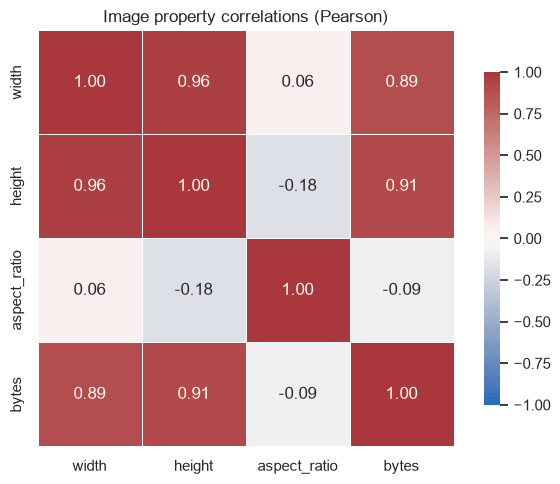

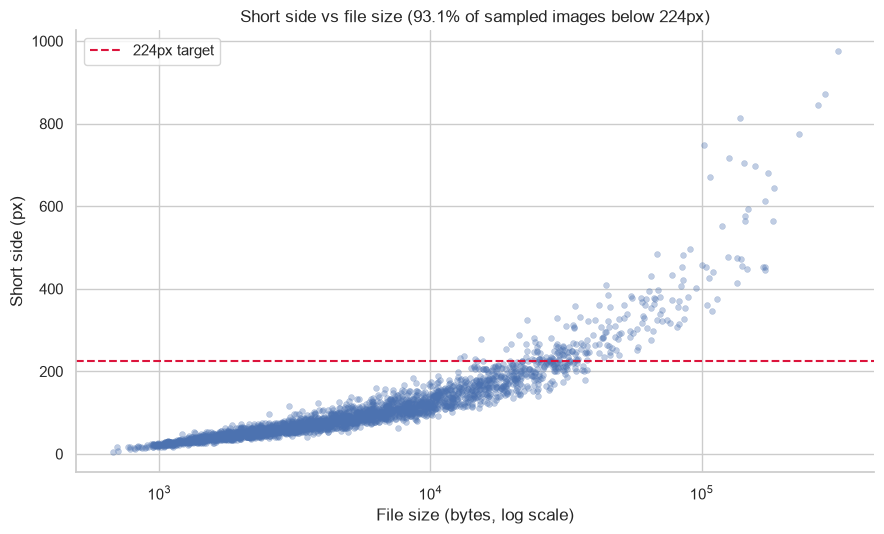

In [6]:
# defining a function that samples images from an archive and records their size, mode and file size
def profile_images(archive, sample_size, seed):
    sample = random.Random(seed).sample(archive.ids, min(sample_size, len(archive)))
    records, corrupted = [], []
    for image_id in sample:
        try:
            data = archive.read_bytes(image_id)
            # verify() checks file integrity but invalidates the image, so the file is opened a second time to decode it
            with Image.open(io.BytesIO(data)) as img:
                img.verify()
            with Image.open(io.BytesIO(data)) as img:
                img.load()
                records.append({
                    "file": image_id,
                    "width": img.width,
                    "height": img.height,
                    "channels": len(img.getbands()),
                    "mode": img.mode,
                    "bytes": archive.file_size(image_id),
                })
        except Exception as exc:
            # keeping the file name and error message of every unreadable image
            corrupted.append((image_id, repr(exc)))
    frame = pd.DataFrame(records)
    # aspect ratio > 1 means a wide image, < 1 a tall one
    frame["aspect_ratio"] = frame["width"] / frame["height"]
    return frame, corrupted


# defining a function that prints size statistics, channel modes and resize effects for one profile
def report_profile(name, frame, corrupted, target):
    stats = frame[["width", "height", "aspect_ratio", "bytes"]].agg(["min", "max", "mean", "median"]).T
    short_side = frame[["width", "height"]].min(axis=1)
    long_side = frame[["width", "height"]].max(axis=1)
    print(f"--- {name}: {len(frame):,} sampled, {len(corrupted)} corrupted ---")
    print(stats.round(2).to_string())
    print("channel modes:", frame["mode"].value_counts().to_dict())
    print(f"non-square (aspect ratio outside 0.95-1.05): {((frame['aspect_ratio'] < 0.95) | (frame['aspect_ratio'] > 1.05)).mean():.1%}")
    print(f"upscaled to {target} (short side < {target}): {(short_side < target).mean():.1%}")
    print(f"downscaled to {target} (long side > {target}): {(long_side > target).mean():.1%}")
    for file_name, error in corrupted[:5]:
        print(f"  corrupted: {file_name} -> {error}")
    print()


# comparing image ids in the labels file with the images found in the training archives
label_ids = set(labels["image_id"])
archive_ids = set(train_archive.ids)
print(f"Train images in archives: {len(train_archive):,} | labelled: {len(label_ids):,} | "
      f"labels without image: {len(label_ids - archive_ids):,} | images without label: {len(archive_ids - label_ids):,}")
print(f"Test images in archive: {len(test_archive):,}\n")
# stopping early if any labelled image is missing from the archives
assert not label_ids - archive_ids, "Some labelled images are missing from the train archives"

# profiling a random sample of the training and test images and reporting the results
target = CONFIG["image_size"][0]
train_profile, train_corrupted = profile_images(train_archive, CONFIG["profile_sample_size"], CONFIG["seed"])
test_profile, test_corrupted = profile_images(test_archive, CONFIG["profile_sample_size"], CONFIG["seed"])
report_profile("train", train_profile, train_corrupted, target)
report_profile("test", test_profile, test_corrupted, target)

# adding the short side of each image (the smaller of width and height) for the plots below
profile = train_profile.assign(short_side=train_profile[["width", "height"]].min(axis=1))

# computing the Pearson correlation between image properties and plotting it as a heatmap
correlation = profile[["width", "height", "aspect_ratio", "bytes"]].corr(method="pearson")
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(
    correlation, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1,
    square=True, linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=ax,
)
ax.set_title("Image property correlations (Pearson)")
fig.tight_layout()
plt.show()

# plotting file size against short side, with the share of images that must be upscaled in the title
upscaled_share = (profile["short_side"] < target).mean()
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.scatterplot(data=profile, x="bytes", y="short_side", alpha=0.35, s=18, edgecolor=None, ax=ax)
ax.axhline(target, color="crimson", linestyle="--", linewidth=1.5, label=f"{target}px target")
ax.set_xscale("log")
ax.set_xlabel("File size (bytes, log scale)")
ax.set_ylabel("Short side (px)")
ax.set_title(f"Short side vs file size ({upscaled_share:.1%} of sampled images below {target}px)")
ax.legend(loc="upper left")
sns.despine(ax=ax)
fig.tight_layout()
plt.show()


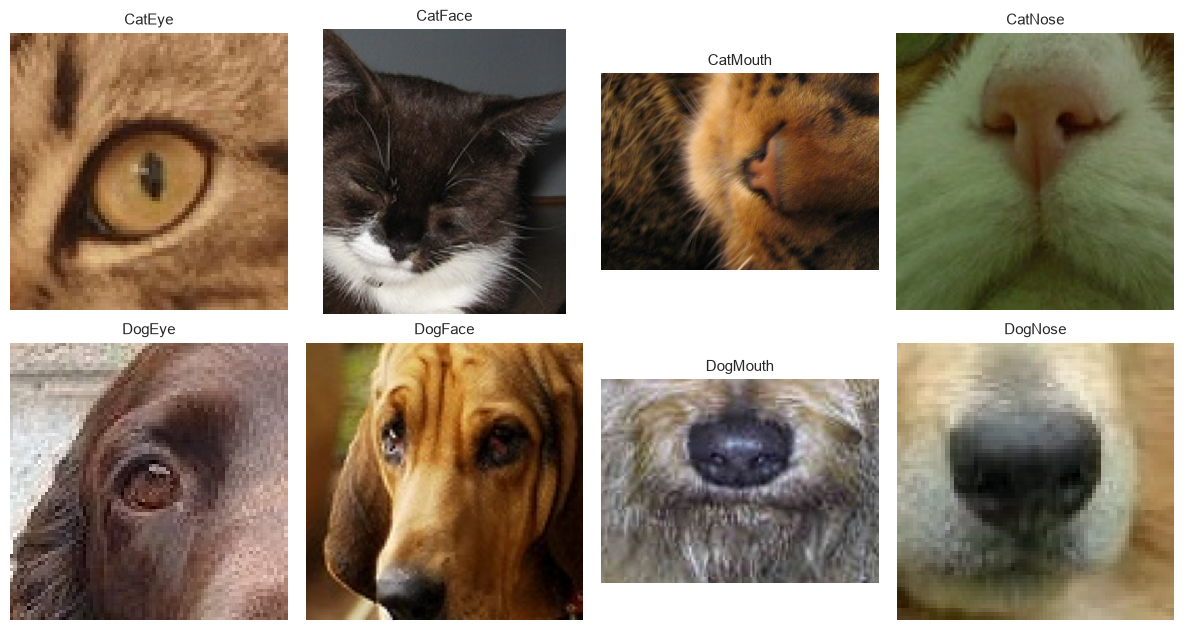

In [7]:
# collecting the image ids of every class
ids_by_class = labels.groupby("class")["image_id"].apply(list)
# laying out the grid with cats on the top row and dogs on the bottom row
grid_layout = [
    ["CatEye", "CatFace", "CatMouth", "CatNose"],
    ["DogEye", "DogFace", "DogMouth", "DogNose"],
]
# drawing one random sample image per class, with a fixed seed so the grid is reproducible
rng = random.Random(CONFIG["seed"])
fig, axes = plt.subplots(2, 4, figsize=(12, 6.5))
for row_axes, row_classes in zip(axes, grid_layout):
    for ax, class_name in zip(row_axes, row_classes):
        ax.imshow(train_archive.open_rgb(rng.choice(ids_by_class[class_name])))
        ax.set_title(class_name, fontsize=11)
        ax.axis("off")
fig.tight_layout()
plt.show()


In [8]:
# COMMIT 2: Leakage-Safe Stratified Split
# Implementation Scope:
# - 80/20 stratified split grouped by file content digest so duplicate images never straddle the split.
# - Per-class balance check and assertions that train and validation share no ids or content.

# computing a content digest per image so duplicate images can be kept on the same side of the split
labels = labels.assign(digest=[train_archive.digest(i) for i in labels["image_id"]])

# taking one fold of a stratified, digest-grouped k-fold (5 folds = 80/20) as the train/validation split
n_splits = round(1 / CONFIG["val_fraction"])
splitter = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=CONFIG["seed"])
train_idx, val_idx = next(splitter.split(labels, labels["class"], groups=labels["digest"]))
train_df = labels.iloc[train_idx].reset_index(drop=True)
val_df = labels.iloc[val_idx].reset_index(drop=True)

# comparing the class balance of the two splits
split_counts = pd.DataFrame({
    "train": train_df["class"].value_counts(),
    "val": val_df["class"].value_counts(),
}).reindex(classes)
split_counts["train_pct"] = split_counts["train"] / split_counts["train"].sum() * 100
split_counts["val_pct"] = split_counts["val"] / split_counts["val"].sum() * 100
print(split_counts.round(2).to_string())

# printing the size and imbalance ratio of each split
for name, frame in (("train", train_df), ("val", val_df)):
    counts = frame["class"].value_counts()
    print(f"{name}: n={len(frame):,} ({len(frame) / len(labels):.1%}) | "
          f"imbalance {counts.max() / counts.min():.3f}:1")

# checking that no image id or image content appears in both splits (no data leakage)
id_overlap = set(train_df["image_id"]) & set(val_df["image_id"])
content_overlap = set(train_df["digest"]) & set(val_df["digest"])
assert len(train_df) + len(val_df) == len(labels)
assert not id_overlap and not content_overlap
print(f"id overlap: {len(id_overlap)} | content overlap: {len(content_overlap)} | "
      f"duplicate-content images grouped: {int(labels['digest'].duplicated(keep=False).sum())}")


          train   val  train_pct  val_pct
class                                    
CatEye    11107  2777      21.81    21.81
DogEye     9264  2316      18.19    18.19
CatFace    5553  1389      10.90    10.91
DogFace    4632  1158       9.10     9.10
CatMouth   5554  1388      10.91    10.90
DogMouth   4632  1158       9.10     9.10
CatNose    5554  1388      10.91    10.90
DogNose    4632  1158       9.10     9.10
train: n=50,928 (80.0%) | imbalance 2.398:1
val: n=12,732 (20.0%) | imbalance 2.398:1
id overlap: 0 | content overlap: 0 | duplicate-content images grouped: 30


In [9]:
# COMMIT 3: Custom Baseline CNN Architecture
# Implementation Scope:
# - Custom Multi-Layer Convolutional Neural Network built from scratch in PyTorch.
# - Sequential blocks implementing Conv2d, BatchNorm2d, ReLU, and MaxPool2d.
# - Fully connected classification head with Dropout regularization.
# - Structural forward pass verification tracking feature map spatial dimensions.


# defining a convolutional block: two 3x3 convolutions, each with batch norm and ReLU, then 2x2 max pooling
def conv_block(in_channels, out_channels):
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True),
        nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True),
        nn.MaxPool2d(kernel_size=2, stride=2),
    )


# defining the baseline CNN: stacked convolutional blocks followed by a small fully connected head
class PetBaselineCNN(nn.Module):
    def __init__(self, num_classes, channels=(32, 64, 128, 256), hidden_dim=256, dropout=0.4):
        super().__init__()
        widths = (3,) + tuple(channels)
        self.blocks = nn.ModuleList(
            [conv_block(c_in, c_out) for c_in, c_out in zip(widths[:-1], widths[1:])]
        )
        # averaging each feature map down to 1x1 so the head works for any input size
        self.pool = nn.AdaptiveAvgPool2d(1)
        # classification head with dropout regularisation
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(dropout),
            nn.Linear(channels[-1], hidden_dim),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, num_classes),
        )
        self.apply(self._init_weights)

    # initialising convolution weights with Kaiming normal (suits ReLU) and linear weights with Xavier uniform
    @staticmethod
    def _init_weights(module):
        if isinstance(module, nn.Conv2d):
            nn.init.kaiming_normal_(module.weight, mode="fan_out", nonlinearity="relu")
        elif isinstance(module, nn.Linear):
            nn.init.xavier_uniform_(module.weight)
            nn.init.zeros_(module.bias)

    # passing the images through every block, pooling, then classifying
    def forward(self, x):
        for block in self.blocks:
            x = block(x)
        return self.classifier(self.pool(x))


In [10]:
# building the model and a random batch to check the architecture end to end
model = PetBaselineCNN(CONFIG["num_classes"], dropout=CONFIG["dropout"]).to(CONFIG["device"])
batch = torch.randn(CONFIG["batch_size"], 3, *CONFIG["image_size"], device=CONFIG["device"])

# registering hooks that record the output shape of every convolutional block
block_shapes = []
hooks = [block.register_forward_hook(lambda m, inp, out: block_shapes.append(tuple(out.shape))) for block in model.blocks]

# running one forward pass in eval mode without gradients
model.eval()
with torch.no_grad():
    logits = model(batch)
# removing the hooks so they cannot affect later forward passes
for hook in hooks:
    hook.remove()
# printing the feature map shapes to confirm the spatial size halves after every block
for index, shape in enumerate(block_shapes, start=1):
    print(f"block {index}: {shape}")
# checking that the logits have the expected shape and contain no NaN or infinite values
expected = (CONFIG["batch_size"], CONFIG["num_classes"])
assert tuple(logits.shape) == expected, f"expected {expected}, got {tuple(logits.shape)}"
assert torch.isfinite(logits).all(), "non-finite logits"
# counting the trainable parameters and showing where the model lives
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"logits: {tuple(logits.shape)} | trainable parameters: {trainable:,} | device: {next(model.parameters()).device}")


block 1: (64, 32, 112, 112)
block 2: (64, 64, 56, 56)
block 3: (64, 128, 28, 28)
block 4: (64, 256, 14, 14)
logits: (64, 8) | trainable parameters: 1,241,064 | device: mps:0


In [11]:
# COMMIT 4: Training Engine, Memory-Mapped Data Pipeline and Checkpointing
# Implementation Scope:
# - BestCheckpoint keeps only the lowest-validation-loss weights (trainable weights only for frozen backbones).
# - uint8 pixel caches on disk, read one batch at a time by MemmapLoader so an 8 GB machine never holds a full split.
# - GPU-side augmentation, run_pass / fit_model with AdamW and cosine annealing; bf16 and TF32 only on CUDA.
# - train_or_load reloads saved runs and stops with a clear error instead of training on a Mac.


class BestCheckpoint:
    """Save the best-validation-loss weights to disk and reload them on any device."""

    def __init__(self, path, trainable_only=False):
        self.path = Path(path)
        self.path.parent.mkdir(parents=True, exist_ok=True)
        self.trainable_only = trainable_only
        self.best_loss = float("inf")

    # saving weights only when the validation loss improves; returns True when a file was written
    def update(self, model, val_loss):
        if val_loss >= self.best_loss:
            return False
        self.best_loss = val_loss
        state = model.state_dict()
        # keeping only trainable weights so frozen backbone weights are not duplicated on disk
        if self.trainable_only:
            names = {name for name, parameter in model.named_parameters() if parameter.requires_grad}
            state = {key: value for key, value in state.items() if key in names}
        torch.save({"trainable_only": self.trainable_only, "state": state}, self.path)
        return True

    # loading either the trainable-only format or a plain state dict
    def load_best(self, model, device):
        payload = torch.load(self.path, map_location=device)
        if isinstance(payload, dict) and set(payload) == {"trainable_only", "state"}:
            state, strict = payload["state"], not payload["trainable_only"]
        else:
            state, strict = payload, True
        result = model.load_state_dict(state, strict=strict)
        # trainable-only files are partial, so missing keys are fine but unexpected keys are not
        assert not result.unexpected_keys, f"unexpected keys in {self.path.name}: {result.unexpected_keys[:3]}"
        return model


In [12]:
# selecting the compute device; pixels stay uint8 on disk and only the current batch becomes a float tensor
device = CONFIG["device"]
use_cuda = device.type == "cuda"
storage_device = device if use_cuda else torch.device("cpu")
height, width = CONFIG["image_size"]


# decoding an image and squashing it to the target size without keeping its aspect ratio
def decode_resized(archive, image_id, size):
    return np.asarray(archive.open_rgb(image_id).resize((size[1], size[0]), Image.Resampling.BILINEAR))


# writing caches as sequential chunks because one 9.6 GB memory-mapped write can crash an 8 GB Mac
# (the macOS page cache is bypassed too); the file is renamed only when complete, so a partial build is never reused
def write_pixel_cache(archive, image_ids, destination, decode, workers, chunk=256):
    destination.parent.mkdir(parents=True, exist_ok=True)
    temporary = destination.with_suffix(".tmp.npy")
    shape = (len(image_ids), *CONFIG["image_size"], 3)
    with open(temporary, "wb") as handle:
        if sys.platform == "darwin":
            fcntl.fcntl(handle.fileno(), fcntl.F_NOCACHE, 1)
        np.lib.format.write_array_header_1_0(
            handle, {"descr": "|u1", "fortran_order": False, "shape": shape})
        with ThreadPoolExecutor(max_workers=workers) as pool:
            for start in range(0, len(image_ids), chunk):
                ids = image_ids[start:start + chunk]
                handle.write(np.stack(list(pool.map(lambda i: decode(archive, i), ids))).tobytes())
        handle.flush()
        os.fsync(handle.fileno())
    temporary.replace(destination)

# using fewer decoding threads on a Mac so the OS keeps enough memory free
cache_workers = min(os.cpu_count() or 4, 32) if use_cuda else 4

# cache rows follow the order of the labels file
all_ids = list(labels["image_id"])
# squash-resize cache used by the CUDA training loaders
cache_path = CONFIG["cache_dir"] / f"train_{height}x{width}.npy"

# building the squash cache on CUDA only; a Mac reloads saved checkpoints and never needs it
has_squash_cache = cache_path.exists() or use_cuda
if has_squash_cache and not cache_path.exists():
    started = time.time()
    write_pixel_cache(train_archive, all_ids, cache_path,
                      lambda a, i: decode_resized(a, i, CONFIG["image_size"]), cache_workers)
    print(f"pixel cache built in {time.time() - started:.0f}s")
if has_squash_cache:
    cache = np.load(cache_path, mmap_mode="r")
    assert cache.shape == (len(all_ids), height, width, 3), "cache is stale; delete it and rebuild"
# mapping each image id to its cache row so any split can be gathered by id
row_of_id = {image_id: row for row, image_id in enumerate(all_ids)}


# loading a whole split into one tensor (only fits on a large GPU; MemmapLoader is the 8 GB alternative)
def load_split(frame):
    rows = np.array([row_of_id[i] for i in frame["image_id"]])
    images = torch.from_numpy(cache[rows]).to(storage_device)
    targets = torch.tensor(frame["class"].map(class_to_idx).to_numpy(), dtype=torch.long, device=storage_device)
    return images, targets

# ImageNet mean and std as broadcastable tensors on the compute device
norm_mean = torch.tensor(CONFIG["imagenet_mean"], device=device).view(1, 3, 1, 1)
norm_std = torch.tensor(CONFIG["imagenet_std"], device=device).view(1, 3, 1, 1)


# defining GPU-side augmentation that is applied to the training batches
def augment_batch(batch, max_degrees=15.0, jitter=0.2):
    """Random flip, rotation, brightness, contrast and saturation jitter on a float batch in [0, 1]."""
    n = batch.size(0)

    def factor():
        return 1 + (torch.rand(n, 1, 1, 1, device=batch.device) * 2 - 1) * jitter

    # random horizontal flip
    flip = torch.rand(n, device=batch.device) < 0.5
    batch = torch.where(flip.view(-1, 1, 1, 1), batch.flip(3), batch)

    # random rotation using an affine grid with reflected borders
    angles = (torch.rand(n, device=batch.device) * 2 - 1) * max_degrees * math.pi / 180
    cos, sin, zeros = angles.cos(), angles.sin(), torch.zeros(n, device=batch.device)
    theta = torch.stack(
        (torch.stack((cos, -sin, zeros), dim=1), torch.stack((sin, cos, zeros), dim=1)), dim=1
    )
    grid = F.affine_grid(theta, batch.shape, align_corners=False)
    batch = F.grid_sample(batch, grid, mode="bilinear", padding_mode="reflection", align_corners=False)

    # random brightness, contrast and saturation jitter
    batch = (batch * factor()).clamp(0, 1)
    gray = batch[:, 0:1] * 0.299 + batch[:, 1:2] * 0.587 + batch[:, 2:3] * 0.114
    mean = gray.mean(dim=(1, 2, 3), keepdim=True)
    batch = ((batch - mean) * factor() + mean).clamp(0, 1)
    gray = batch[:, 0:1] * 0.299 + batch[:, 1:2] * 0.587 + batch[:, 2:3] * 0.114
    return ((batch - gray) * factor() + gray).clamp(0, 1)


# defining the loader for splits that already sit in memory
class InMemoryLoader:
    """Batch loader over image and target tensors that already sit in memory (GPU-sized splits only)."""

    def __init__(self, images, targets, batch_size, shuffle, augment=False, drop_last=False, seed=0):
        self.images, self.targets = images, targets
        self.batch_size, self.shuffle = batch_size, shuffle
        self.augment, self.drop_last = augment, drop_last
        self.generator = torch.Generator().manual_seed(seed)

    def __len__(self):
        count = self.images.size(0)
        return count // self.batch_size if self.drop_last else math.ceil(count / self.batch_size)

    def __iter__(self):
        count = self.images.size(0)
        order = torch.randperm(count, generator=self.generator) if self.shuffle else torch.arange(count)
        order = order.to(self.images.device)
        for step in range(len(self)):
            index = order[step * self.batch_size:(step + 1) * self.batch_size]
            batch = self.images[index].to(device, non_blocking=True).permute(0, 3, 1, 2).float().div_(255)
            if self.augment:
                batch = augment_batch(batch)
            batch = ((batch - norm_mean) / norm_std).contiguous(memory_format=torch.channels_last)
            yield batch, self.targets[index].to(device, non_blocking=True)


# defining the loader that reads one batch at a time from the memory-mapped cache
class MemmapLoader:
    """Batch loader that reads uint8 pixels straight from a memory-mapped .npy file.

    Only one batch is resident in RAM at a time, so an 8 GB machine can iterate the
    full train/val/test caches without copying them into tensors first.
    """

    def __init__(self, pixels, targets, batch_size, rows=None, shuffle=False,
                 augment=False, drop_last=False, seed=0):
        self.pixels, self.targets, self.batch_size = pixels, targets, batch_size
        self.rows = np.arange(len(targets)) if rows is None else np.asarray(rows)
        self.shuffle, self.augment, self.drop_last = shuffle, augment, drop_last
        self.generator = torch.Generator().manual_seed(seed)
        self.start_step = 0

    def __len__(self):
        count = len(self.rows)
        return count // self.batch_size if self.drop_last else math.ceil(count / self.batch_size)

    def __iter__(self):
        # visiting rows in a fixed order, or in a seeded random order when shuffling
        order = torch.randperm(len(self.rows), generator=self.generator).numpy() if self.shuffle else np.arange(len(self.rows))
        # starting part-way through when a prediction run is being resumed
        first_step, self.start_step = self.start_step, 0
        for step in range(first_step, len(self)):
            chosen = order[step * self.batch_size:(step + 1) * self.batch_size]
            # gathering the batch from disk, then converting uint8 NHWC to normalised float NCHW on the device
            pixels = np.ascontiguousarray(self.pixels[self.rows[chosen]])
            batch = torch.from_numpy(pixels).to(device).permute(0, 3, 1, 2).float().div_(255)
            if self.augment:
                batch = augment_batch(batch)
            batch = ((batch - norm_mean) / norm_std).contiguous(memory_format=torch.channels_last)
            yield batch, self.targets[torch.from_numpy(chosen)].to(device)


# building train, validation and test loaders over the pixel caches
def build_loaders(train_cache, test_cache=None):
    rows = lambda frame: np.array([row_of_id[i] for i in frame["image_id"]])
    targets = lambda frame: torch.tensor(frame["class"].map(class_to_idx).to_numpy(), dtype=torch.long)
    train = MemmapLoader(train_cache, targets(train_df), CONFIG["train_batch_size"], rows(train_df),
                         shuffle=True, augment=True, drop_last=True, seed=CONFIG["seed"])
    val = MemmapLoader(train_cache, targets(val_df), CONFIG["eval_batch_size"], rows(val_df))
    test = None if test_cache is None else MemmapLoader(
        test_cache, torch.full((len(test_cache),), -1, dtype=torch.long), CONFIG["eval_batch_size"])
    return train, val, test

# creating the loaders and reporting their sizes
if has_squash_cache:
    train_loader, val_loader, _ = build_loaders(cache)
    print(f"device: {device} | train: {len(train_loader.rows):,} | val: {len(val_loader.rows):,} images | "
          f"pixels memory-mapped from {cache_path.name}")
else:
    print(f"device: {device} | squash cache skipped; loaders are built on the letterbox caches in the next stage")


device: mps | train: 50,928 | val: 12,732 images | pixels memory-mapped from train_224x224.npy


In [13]:
# running one pass over a loader: trains when an optimizer is given, otherwise evaluates
def run_pass(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)
    # accumulating loss and correct counts on the device to avoid a CPU sync every batch
    loss_sum = torch.zeros((), device=device)
    correct = torch.zeros((), device=device, dtype=torch.long)
    seen = 0

    with torch.set_grad_enabled(training):
        for images, targets in loader:
            # using bf16 autocast on CUDA only; MPS and CPU stay in float32
            with torch.autocast(device_type=device.type, dtype=torch.bfloat16, enabled=use_cuda):
                logits = model(images)
            loss = criterion(logits.float(), targets)

            if training:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                optimizer.step()

            loss_sum += loss.detach() * targets.size(0)
            correct += (logits.argmax(dim=1) == targets).sum()
            seen += targets.size(0)

    return loss_sum.item() / seen, correct.item() / seen


# training with AdamW and cosine annealing while keeping the best-validation-loss checkpoint
def fit_model(model, name, epochs, learning_rate=None, param_groups=None, weight_decay=None):
    """Train with AdamW and cosine annealing, keep the best-validation-loss checkpoint, return the history."""
    weight_decay = CONFIG["weight_decay"] if weight_decay is None else weight_decay
    # re-seeding so every run starts from the same state
    seed_everything(CONFIG["seed"])
    # enabling faster non-deterministic CUDA kernels and TF32 (CUDA only)
    if use_cuda:
        torch.backends.cudnn.deterministic = False
        torch.backends.cudnn.benchmark = True
        torch.backends.cuda.matmul.allow_tf32 = True
        torch.backends.cudnn.allow_tf32 = True
    train_loader.generator.manual_seed(CONFIG["seed"])

    model = model.to(device)
    if use_cuda:
        model = model.to(memory_format=torch.channels_last)
    # counting trainable and frozen parameters for the log line
    trainable = [p for p in model.parameters() if p.requires_grad]
    frozen_count = sum(p.numel() for p in model.parameters() if not p.requires_grad)
    print(f"{name} | trainable {sum(p.numel() for p in trainable):,} | frozen {frozen_count:,}")

    criterion = nn.CrossEntropyLoss()
    # using one parameter group, or caller-supplied groups for discriminative learning rates
    groups = param_groups if param_groups is not None else [{"params": trainable, "lr": learning_rate}]
    optimizer = torch.optim.AdamW(groups, weight_decay=weight_decay)
    # decaying the learning rate with a cosine curve down to eta_min over all epochs
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=epochs, eta_min=CONFIG["eta_min"]
    )
    # saving trainable weights only when part of the model is frozen
    checkpoint = BestCheckpoint(CONFIG["checkpoint_dir"] / f"{name}.pt", trainable_only=frozen_count > 0)

    # recording metrics per epoch; the CSV is rewritten every epoch so a crash loses nothing
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [], "lr": []}
    history_path = CONFIG["history_dir"] / f"{name}_history.csv"
    history_path.parent.mkdir(parents=True, exist_ok=True)
    run_started = time.time()

    for epoch in range(1, epochs + 1):
        epoch_started = time.time()
        lr = optimizer.param_groups[0]["lr"]
        train_loss, train_acc = run_pass(model, train_loader, criterion, optimizer)
        val_loss, val_acc = run_pass(model, val_loader, criterion)
        scheduler.step()

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        history["lr"].append(lr)
        pd.DataFrame(history).to_csv(history_path, index=False)

        improved = checkpoint.update(model, val_loss)
        elapsed = time.time() - epoch_started
        print(
            f"epoch {epoch:02d}/{epochs} | lr {lr:.2e} | "
            f"train loss {train_loss:.4f} acc {train_acc:.4f} | "
            f"val loss {val_loss:.4f} acc {val_acc:.4f} | "
            f"{elapsed:.0f}s ({len(train_loader) * CONFIG['train_batch_size'] / elapsed:,.0f} img/s){' | saved' if improved else ''}"
        )

    # reloading the best weights and re-evaluating them for the final summary
    best_epoch = int(np.argmin(history["val_loss"])) + 1
    checkpoint.load_best(model, device)
    best_loss, best_acc = run_pass(model, val_loader, criterion)
    print(f"total {(time.time() - run_started) / 60:.1f} min | best epoch {best_epoch} | "
          f"val loss {best_loss:.4f} | val accuracy {best_acc:.4f}\n")
    return history


# loading a saved run when possible; otherwise training, which is only allowed when enabled for the device
def train_or_load(model, name, **fit_arguments):
    """Load a saved run when checkpoint and history exist; otherwise train (CUDA, or when local training is allowed)."""
    history_path = CONFIG["history_dir"] / f"{name}_history.csv"
    checkpoint_path = CONFIG["checkpoint_dir"] / f"{name}.pt"
    # reusing the saved run when both files exist and the history length matches the requested epochs
    if history_path.exists() and checkpoint_path.exists() and not CONFIG["retrain"]:
        history = pd.read_csv(history_path).to_dict(orient="list")
        if len(history["val_loss"]) == fit_arguments["epochs"]:
            BestCheckpoint(checkpoint_path).load_best(model.to(device), device)
            best = int(np.argmin(history["val_loss"]))
            print(f"{name}: loaded saved run | {len(history['val_loss'])} epochs | best epoch {best + 1} | "
                  f"val loss {history['val_loss'][best]:.4f} | val accuracy {history['val_acc'][best]:.4f}\n")
            return history
    # stopping with a clear message instead of starting a multi-hour run on a Mac
    if not CONFIG["allow_local_training"]:
        raise RuntimeError(
            f"{name}: no saved checkpoint at {checkpoint_path} and training on {device} is disabled. "
            f"Extract results.tar.gz, or set CONFIG['allow_local_training'] = True "
            f"(batch size {CONFIG['train_batch_size']}; expect hours on Apple Silicon)."
        )
    return fit_model(model, name, **fit_arguments)


In [14]:
# COMMIT 5: Baseline CNN Training and Evaluation
# Implementation Scope:
# - 10 epochs of AdamW with cosine annealing over the full 50,928-image training split.
# - Validation on the full 12,732-image held-out split after every epoch.
# - Saved history and best weights are reloaded on later runs instead of retraining; on a Mac a missing
#   checkpoint raises an error rather than starting a multi-hour run.

# training the baseline CNN from scratch, or loading the saved run
baseline_model = PetBaselineCNN(CONFIG["num_classes"], dropout=CONFIG["dropout"])
baseline_history = train_or_load(baseline_model, "baseline_cnn", epochs=10, learning_rate=1e-3)


baseline_cnn: loaded saved run | 10 epochs | best epoch 10 | val loss 0.1179 | val accuracy 0.9593



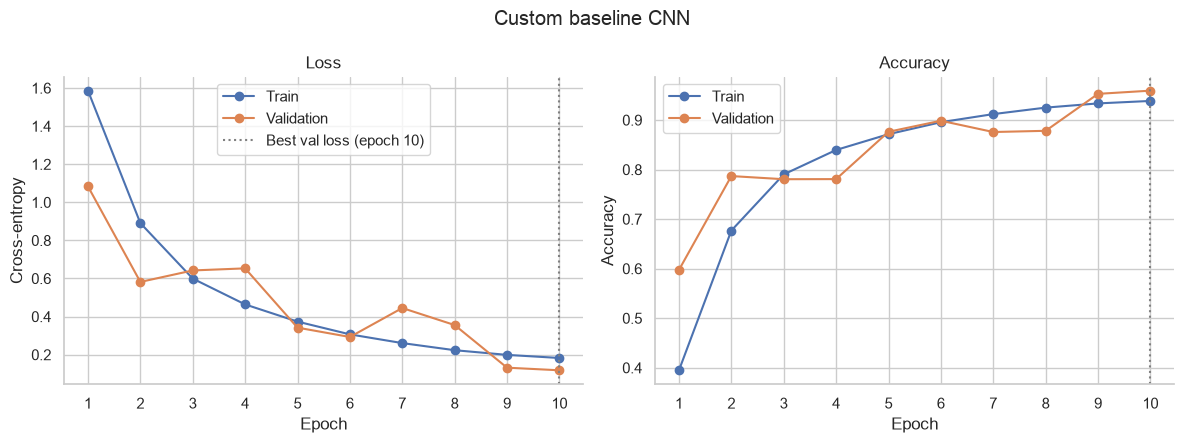

In [15]:
# defining a function that plots loss and accuracy per epoch and marks the epoch with the best validation loss
def plot_history(history, title):
    epoch_axis = np.arange(1, len(history["train_loss"]) + 1)
    best_epoch = int(np.argmin(history["val_loss"])) + 1

    fig, (loss_ax, acc_ax) = plt.subplots(1, 2, figsize=(12, 4.5))

    # drawing the loss curves on the left
    loss_ax.plot(epoch_axis, history["train_loss"], marker="o", label="Train")
    loss_ax.plot(epoch_axis, history["val_loss"], marker="o", label="Validation")
    loss_ax.axvline(best_epoch, color="gray", linestyle=":", label=f"Best val loss (epoch {best_epoch})")
    loss_ax.set_title("Loss")
    loss_ax.set_xlabel("Epoch")
    loss_ax.set_ylabel("Cross-entropy")
    loss_ax.legend()

    # drawing the accuracy curves on the right
    acc_ax.plot(epoch_axis, history["train_acc"], marker="o", label="Train")
    acc_ax.plot(epoch_axis, history["val_acc"], marker="o", label="Validation")
    acc_ax.axvline(best_epoch, color="gray", linestyle=":")
    acc_ax.set_title("Accuracy")
    acc_ax.set_xlabel("Epoch")
    acc_ax.set_ylabel("Accuracy")
    acc_ax.legend()

    # using whole epochs as x ticks, removing the top and right spines and adding the overall title
    for ax in (loss_ax, acc_ax):
        ax.set_xticks(epoch_axis)
        sns.despine(ax=ax)
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()

# plotting the baseline CNN history
plot_history(baseline_history, "Custom baseline CNN")


In [ ]:
# COMMIT 6: Frozen-Backbone Transfer Learning
# Implementation Scope:
# - Pretrained torchvision backbone (weights=DEFAULT) with every backbone parameter frozen.
# - Custom Dropout + Linear head mapping to the 8 target classes.
# - Backbone kept in eval mode so frozen normalisation layers never update.
# - 5 epochs over the full dataset, compared against the baseline CNN.


# defining a pretrained backbone with frozen weights and a new trainable classification head
class TransferClassifier(nn.Module):
    def __init__(self, name, num_classes, dropout):
        super().__init__()
        # loading ImageNet weights (downloaded once on first use)
        self.backbone = getattr(models, name)(weights="DEFAULT")
        # freezing every backbone parameter
        for parameter in self.backbone.parameters():
            parameter.requires_grad = False
        # removing the original classifier and recording its input width (ResNet uses fc, ConvNeXt uses classifier)
        if hasattr(self.backbone, "fc"):
            features = self.backbone.fc.in_features
            self.backbone.fc = nn.Identity()
        else:
            features = self.backbone.classifier[-1].in_features
            self.backbone.classifier[-1] = nn.Identity()
        # new head that maps backbone features to the 8 target classes
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(features, num_classes))

    # keeping the backbone in eval mode so frozen normalisation layers never update
    def train(self, mode=True):
        super().train(mode)
        self.backbone.eval()
        return self

    def forward(self, x):
        return self.head(self.backbone(x))


# training the frozen-backbone model, or loading the saved run
transfer_name = f"transfer_{CONFIG['backbone']}"
transfer_model = TransferClassifier(CONFIG["backbone"], CONFIG["num_classes"], CONFIG["head_dropout"])
transfer_history = train_or_load(transfer_model, transfer_name, epochs=5, learning_rate=2e-3) 


transfer_convnext_tiny: loaded saved run | 5 epochs | best epoch 5 | val loss 0.1507 | val accuracy 0.9541



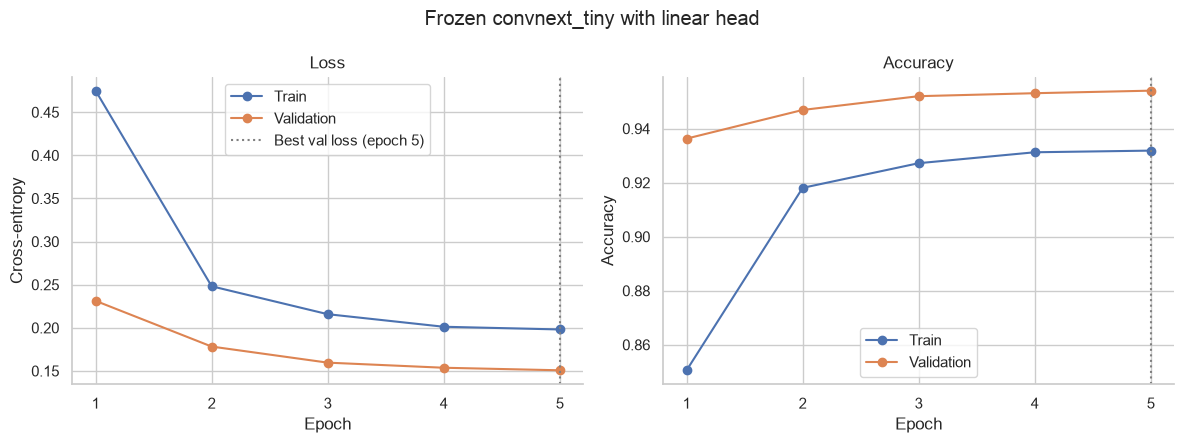

In [17]:
# plotting the frozen-backbone history
plot_history(transfer_history, f"Frozen {CONFIG['backbone']} with linear head")


In [18]:
# COMMIT 7: Aspect Ratio Preservation and Test-Shift Optimization
# Implementation Scope:
# - Longest-side resize with centred reflection or constant padding to 224x224 instead of squashing.
# - Letterboxed pixel caches for the labelled and test images, built once from the zip archives.
# - Training, validation and test loaders rebuilt as memory-mapped loaders on the letterboxed pixels.


# resizing the longest side to the target and padding the rest, so the aspect ratio is preserved
def letterbox(image, size, mode):
    target_h, target_w = size
    scale = min(target_h / image.height, target_w / image.width)
    new_w, new_h = max(1, round(image.width * scale)), max(1, round(image.height * scale))
    resized = np.asarray(image.resize((new_w, new_h), Image.Resampling.BILINEAR))
    pad_h, pad_w = target_h - new_h, target_w - new_w
    pad = ((pad_h // 2, pad_h - pad_h // 2), (pad_w // 2, pad_w - pad_w // 2), (0, 0))
    return np.pad(resized, pad, mode=mode)


def decode_letterboxed(archive, image_id, size, mode):
    return letterbox(archive.open_rgb(image_id), size, mode)


# naming the letterbox caches after the padding mode so different modes never share a file
pad_mode = CONFIG["letterbox_mode"]
test_ids = list(test_archive.ids)
train_cache_path = CONFIG["cache_dir"] / f"train_{height}x{width}_letterbox_{pad_mode}.npy"
test_cache_path = CONFIG["cache_dir"] / f"test_{height}x{width}_letterbox_{pad_mode}.npy"

# building the letterbox caches that do not exist yet (needs about 14 GB of free disk)
for path, archive, ids in ((train_cache_path, train_archive, all_ids), (test_cache_path, test_archive, test_ids)):
    if not path.exists():
        started = time.time()
        write_pixel_cache(
            archive, ids, path,
            lambda a, i: decode_letterboxed(a, i, CONFIG["image_size"], pad_mode),
            cache_workers,
        )
        print(f"{path.name} built in {time.time() - started:.0f}s")

# dropping the old loaders so their memory can be released
for stale in ("train_loader", "val_loader"):
    globals().pop(stale, None)
gc.collect()
if use_cuda:
    torch.cuda.empty_cache()

# opening the caches memory-mapped and checking they match the labels file
cache = np.load(train_cache_path, mmap_mode="r")
assert cache.shape == (len(all_ids), height, width, 3), "letterbox cache is stale; delete it and rebuild"
test_cache = np.load(test_cache_path, mmap_mode="r")
# rebuilding all three loaders on the letterboxed pixels
train_loader, val_loader, test_loader = build_loaders(cache, test_cache)
print(f"letterbox ({pad_mode}) | train: {len(train_loader.rows):,} | val: {len(val_loader.rows):,} | "
      f"test: {len(test_cache):,} images | memory-mapped")


letterbox (reflect) | train: 50,928 | val: 12,732 | test: 29,443 images | memory-mapped


batch (64, 3, 224, 224) -> logits (64, 8) | finite: True


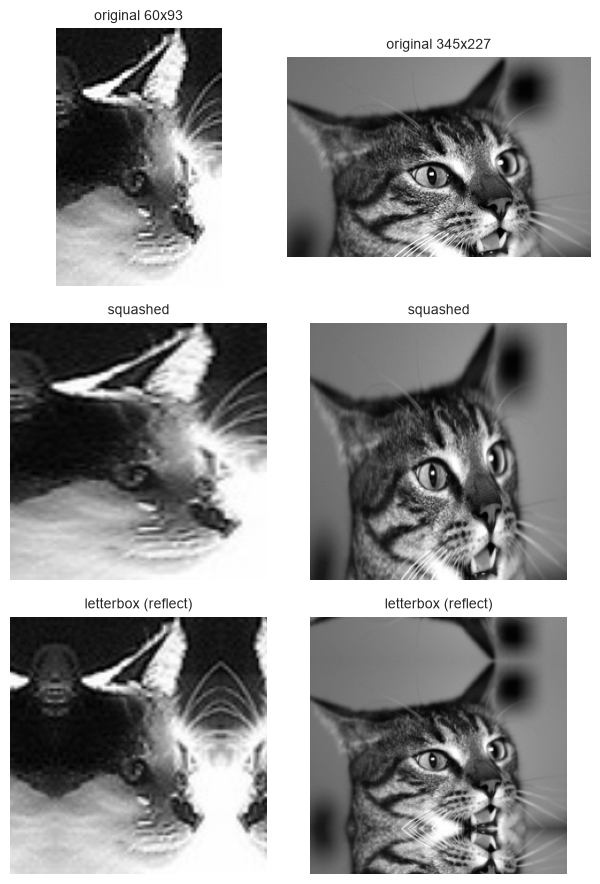

In [19]:
# pushing one validation batch through the transfer model as a sanity check
probe_loader = MemmapLoader(val_loader.pixels, val_loader.targets, 64, val_loader.rows)
probe_images, probe_targets = next(iter(probe_loader))
assert tuple(probe_images.shape) == (64, 3, *CONFIG["image_size"]), "unexpected batch shape"

transfer_model.eval()
with torch.no_grad(), torch.autocast(device_type=device.type, dtype=torch.bfloat16, enabled=use_cuda):
    probe_logits = transfer_model(probe_images)
assert tuple(probe_logits.shape) == (64, CONFIG["num_classes"]), "unexpected logits shape"
print(f"batch {tuple(probe_images.shape)} -> logits {tuple(probe_logits.shape)} | "
      f"finite: {bool(torch.isfinite(probe_logits).all())}")

# looking for validation images that are clearly non-square (aspect ratio of 1.5 or more)
shown = []
for image_id in val_df["image_id"].iloc[:500]:
    with Image.open(io.BytesIO(train_archive.read_bytes(image_id))) as img:
        w, h = img.size
    if max(w / h, h / w) >= 1.5:
        shown.append((image_id, w, h))
    if len(shown) == 4:
        break
assert shown, "no clearly non-square validation images found"

# comparing the original, the squashed and the letterboxed version of each image
fig, axes = plt.subplots(3, len(shown), figsize=(3.2 * len(shown), 9), squeeze=False)
for column, (image_id, w, h) in enumerate(shown):
    axes[0, column].imshow(train_archive.open_rgb(image_id))
    axes[0, column].set_title(f"original {w}x{h}", fontsize=10)
    axes[1, column].imshow(decode_resized(train_archive, image_id, CONFIG["image_size"]))
    axes[1, column].set_title("squashed", fontsize=10)
    axes[2, column].imshow(decode_letterboxed(train_archive, image_id, CONFIG["image_size"], pad_mode))
    axes[2, column].set_title(f"letterbox ({pad_mode})", fontsize=10)
for ax in axes.ravel():
    ax.axis("off")
fig.tight_layout()
plt.show()


In [20]:
# COMMIT 8: Target Class Error Analysis and Fine-Tuning Optimization
# Implementation Scope:
# - Unfreeze the deepest backbone stage and its final normalisation, keeping earlier stages locked.
# - Discriminative learning rates: higher for the classification head, much lower for unfrozen blocks.
# - 5 epochs of cosine-annealed AdamW starting from the trained frozen-backbone head.
# - Compact checkpoint holding only the trained weights so it stays small enough for GitHub.

import copy


# unfreezing the deepest backbone blocks and the final normalisation layer
def unfreeze_upper_blocks(model, first_block):
    assert hasattr(model.backbone, "features"), "block-index unfreezing expects a features-style backbone"
    for block in model.backbone.features[first_block:]:
        for parameter in block.parameters():
            parameter.requires_grad = True
    for parameter in model.backbone.classifier[0].parameters():
        parameter.requires_grad = True


def finetune_groups(model):
    """Optimizer groups: classification head at the head learning rate, unfrozen backbone blocks at the lower one."""
    head = list(model.head.parameters())
    head_ids = {id(p) for p in head}
    backbone = [p for p in model.parameters() if p.requires_grad and id(p) not in head_ids]
    return [
        {"params": head, "lr": CONFIG["finetune_head_lr"]},
        {"params": backbone, "lr": CONFIG["finetune_backbone_lr"]},
    ]


# starting fine-tuning from a copy of the trained frozen-backbone model
finetune_name = f"finetune_{CONFIG['backbone']}"
finetune_model = copy.deepcopy(transfer_model)
unfreeze_upper_blocks(finetune_model, CONFIG["unfreeze_from"])

# fine-tuning with discriminative learning rates, or loading the saved run
finetune_history = train_or_load(
    finetune_model, finetune_name, epochs=5, param_groups=finetune_groups(finetune_model)
)


finetune_convnext_tiny: loaded saved run | 5 epochs | best epoch 5 | val loss 0.0484 | val accuracy 0.9844



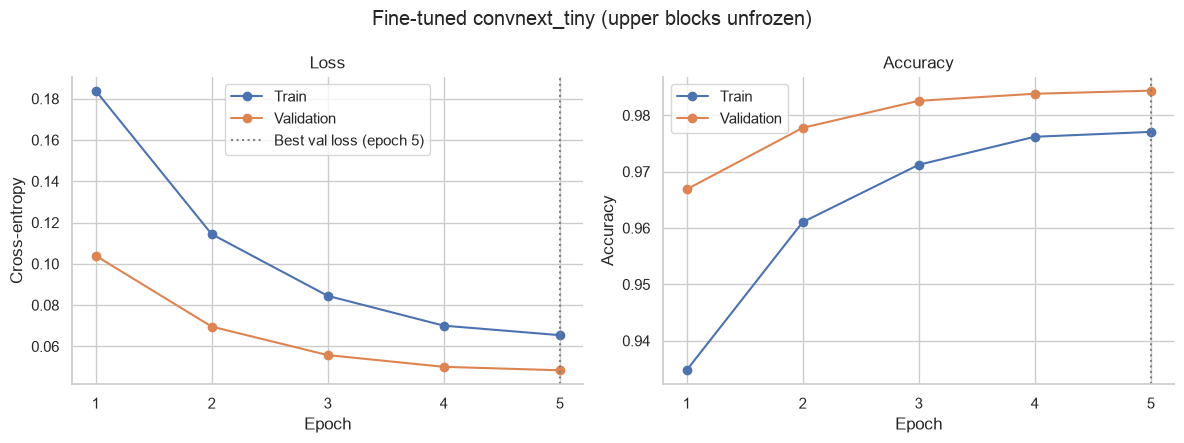

In [21]:
# plotting the fine-tuning history
plot_history(finetune_history, f"Fine-tuned {CONFIG['backbone']} (upper blocks unfrozen)")


In [22]:
# COMMIT 9: Diagnostic Performance Metrics and Confusion Matrices
# Implementation Scope:
# - Reload the best fine-tuned checkpoint from disk and evaluate the full 12,732-image validation split.
# - 8-class confusion matrix with a direct count of Mouth versus Nose confusions.
# - Per-class precision, recall and F1 with the macro-averaged F1.
# - Prediction cache: each model's plain and flip-TTA probabilities are computed in one pass and saved to
#   saved_results/predictions/, so later cells and later runs reuse them until the checkpoint changes.

# importing the metric helpers
from sklearn.metrics import classification_report, confusion_matrix, f1_score


# defining a helper that releases memory before long inference runs
def free_memory():
    """Release Python and accelerator memory before a long inference run."""
    gc.collect()
    if device.type == "mps":
        torch.mps.empty_cache()
    elif use_cuda:
        torch.cuda.empty_cache()


# defining one inference pass that returns plain and flip-TTA probabilities, with progress and resume
@torch.no_grad()
def predict_both(model, loader, partial_path=None, stamp=0, log_every=25, save_every=100):
    """Plain and flip-TTA probabilities in two forward passes per batch, with progress, ETA and resume."""
    free_memory()
    model.eval()
    plain, tta, targets, done = [], [], [], 0
    if partial_path is not None and partial_path.exists():
        saved = np.load(partial_path)
        if int(saved["stamp"]) == stamp and int(saved["batch_size"]) == loader.batch_size:
            plain, tta, targets = [saved["plain"]], [saved["tta"]], [saved["targets"]]
            done = int(saved["batches"])
            loader.start_step = done
            print(f"  resuming from batch {done}/{len(loader)}")
    total, seen, started = len(loader), 0, time.time()
    for step, (images, batch_targets) in enumerate(loader, start=done):
        with torch.autocast(device_type=device.type, dtype=torch.bfloat16, enabled=use_cuda):
            first = model(images).float().softmax(dim=1)
            mirrored = model(images.flip(3)).float().softmax(dim=1)
        plain.append(first.cpu().numpy())
        tta.append(((first + mirrored) / 2).cpu().numpy())
        targets.append(batch_targets.cpu().numpy())
        seen += len(images)
        if (step + 1) % log_every == 0 or step + 1 == total:
            rate = seen / (time.time() - started)
            print(f"  batch {step + 1}/{total} | {rate:,.0f} img/s | about "
                  f"{(total - step - 1) * loader.batch_size / rate / 60:.1f} min left")
        if partial_path is not None and (step + 1) % save_every == 0 and step + 1 < total:
            np.savez(partial_path, plain=np.concatenate(plain), tta=np.concatenate(tta),
                     targets=np.concatenate(targets), batches=step + 1, stamp=stamp, batch_size=loader.batch_size)
    if partial_path is not None and partial_path.exists():
        partial_path.unlink()
    return np.concatenate(plain), np.concatenate(tta), np.concatenate(targets)


# defining the prediction cache that saves probabilities per model and split in saved_results/predictions/
def cached_predictions(name, split, loader, model=None, make_model=None):
    """Return (plain, tta, targets), reusing the saved file while the checkpoint is unchanged.

    Delete saved_results/predictions/ to force a recompute; `make_model` builds the model only on a cache miss.
    """
    checkpoint = CONFIG["checkpoint_dir"] / f"{name}.pt"
    path = CONFIG["prediction_dir"] / f"{name}_{split}.npz"
    stamp = checkpoint.stat().st_mtime_ns if checkpoint.exists() else 0
    if path.exists():
        saved = np.load(path)
        if int(saved["stamp"]) == stamp and len(saved["targets"]) == len(loader.rows):
            return saved["plain"], saved["tta"], saved["targets"]
    model = model if model is not None else make_model()
    print(f"{name} | {split}: computing predictions (saved to {path.name} when finished)")
    plain, tta, targets = predict_both(model, loader, path.with_suffix(".partial.npz"), stamp)
    np.savez(path, plain=plain, tta=tta, targets=targets, stamp=stamp)
    return plain, tta, targets


# defining a helper that lists the saved prediction files
def prediction_files():
    """Print every finished prediction file so a repeat run can be checked at a glance."""
    for path in sorted(CONFIG["prediction_dir"].glob("*.npz")):
        if not path.name.endswith(".partial.npz"):
            print(f"  {path.name} ({path.stat().st_size / 1e6:.1f} MB)")


# reloading the best fine-tuned checkpoint
final_model = TransferClassifier(CONFIG["backbone"], CONFIG["num_classes"], CONFIG["head_dropout"]).to(device)
BestCheckpoint(CONFIG["checkpoint_dir"] / f"{finetune_name}.pt").load_best(final_model, device)

# predicting the validation split with and without flip TTA from the cache
val_probabilities, val_tta_probabilities, val_true = cached_predictions(finetune_name, "val", val_loader, final_model)
# converting probabilities to class indices and comparing plain and TTA accuracy
val_pred = val_probabilities.argmax(axis=1)
print(f"validation images: {len(val_true):,} | accuracy {(val_pred == val_true).mean():.4f} | "
      f"with flip TTA {(val_tta_probabilities.argmax(axis=1) == val_true).mean():.4f}")


validation images: 12,732 | accuracy 0.9845 | with flip TTA 0.9858


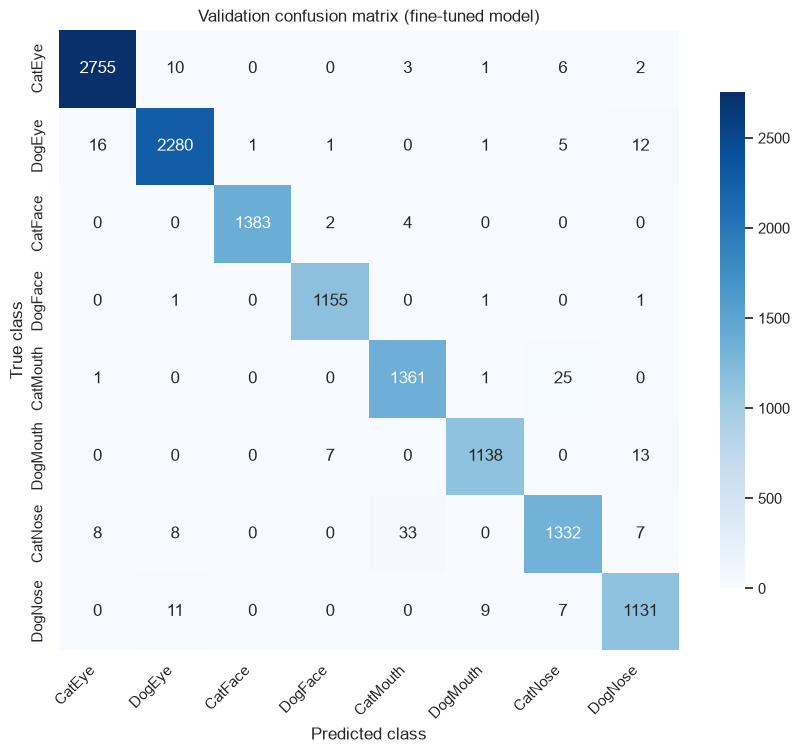

Mouth/Nose confusions: 80 of 197 errors (40.6%)


In [23]:
# counting how often every true class is predicted as every other class
matrix = confusion_matrix(val_true, val_pred, labels=np.arange(CONFIG["num_classes"]))

# plotting the confusion matrix as an annotated heatmap
fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(
    matrix, annot=True, fmt="d", cmap="Blues", square=True, cbar_kws={"shrink": 0.8},
    xticklabels=CONFIG["classes"], yticklabels=CONFIG["classes"], ax=ax,
)
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")
ax.set_title("Validation confusion matrix (fine-tuned model)")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
fig.tight_layout()
plt.show()

# measuring how many errors confuse Mouth with Nose within the same animal
index = {name: i for i, name in enumerate(CONFIG["classes"])}
mouth_nose = sum(
    matrix[index[a], index[b]] + matrix[index[b], index[a]]
    for a, b in (("CatMouth", "CatNose"), ("DogMouth", "DogNose"))
)
errors = int(matrix.sum() - np.trace(matrix))
print(f"Mouth/Nose confusions: {int(mouth_nose)} of {errors} errors ({mouth_nose / max(errors, 1):.1%})")


In [24]:
# reporting per-class precision, recall and F1
print(classification_report(val_true, val_pred, target_names=CONFIG["classes"], digits=4))
print(f"macro F1: {f1_score(val_true, val_pred, average='macro'):.4f}")


              precision    recall  f1-score   support

      CatEye     0.9910    0.9921    0.9915      2777
      DogEye     0.9870    0.9845    0.9857      2316
     CatFace     0.9993    0.9957    0.9975      1389
     DogFace     0.9914    0.9974    0.9944      1158
    CatMouth     0.9714    0.9805    0.9760      1388
    DogMouth     0.9887    0.9827    0.9857      1158
     CatNose     0.9687    0.9597    0.9642      1388
     DogNose     0.9700    0.9767    0.9733      1158

    accuracy                         0.9845     12732
   macro avg     0.9834    0.9837    0.9835     12732
weighted avg     0.9845    0.9845    0.9845     12732

macro F1: 0.9835


In [25]:
# COMMIT 10: Production Inference Engine and Leaderboard Submission Generator
# Implementation Scope:
# - Flip test-time augmentation: original and mirrored probabilities are averaged before the argmax.
# - Predictions mapped back to the exact class names and ordered like sample_submission.csv.
# - submission.csv written without an index and verified for header, row count and labels. This first-model
#   submission is optional (CONFIG["write_first_submission"], off by default) because the submitted file is
#   produced from the robust models in the last cell.

# skipping the test pass unless the first-model submission is requested, because it is not the submitted model
if CONFIG["write_first_submission"]:
    _, test_probabilities, _ = cached_predictions(finetune_name, "test", test_loader, final_model)
    test_pred = test_probabilities.argmax(axis=1)
    predicted_names = [CONFIG["classes"][i] for i in test_pred]
    # checking that there is exactly one prediction per test image
    assert len(predicted_names) == len(test_ids) == 29_443, "unexpected number of test predictions"
    print(pd.Series(predicted_names).value_counts().reindex(CONFIG["classes"]).to_string())
else:
    print("first-model submission skipped (set CONFIG['write_first_submission'] = True to produce it)")


first-model submission skipped (set CONFIG['write_first_submission'] = True to produce it)


In [26]:
if CONFIG["write_first_submission"]:
    # reading the sample submission to copy its image order
    sample = pd.read_csv(CONFIG["sample_submission_csv"], dtype={"image_id": str})
    predicted_by_number = pd.Series(predicted_names, index=[int(i) for i in test_ids])
    assert set(sample["image_id"].astype(int)) == set(predicted_by_number.index), "sample ids differ from test ids"

    # aligning predictions to the sample submission order
    submission = pd.DataFrame({
        "image_id": sample["image_id"],
        "class": predicted_by_number.loc[sample["image_id"].astype(int)].to_numpy(),
    })
    submission.to_csv(CONFIG["submission_path"], index=False)


In [27]:
if CONFIG["write_first_submission"]:
    # re-reading the file and checking header, row count and labels
    written = pd.read_csv(CONFIG["submission_path"], dtype={"image_id": str})
    print(written.head(5).to_string(index=False))
    with open(CONFIG["submission_path"]) as handle:
        lines = handle.read().splitlines()
    assert lines[0] == "image_id,class" and len(lines) == 29_444, "submission file does not match the required layout"
    assert set(written["class"]) <= set(CONFIG["classes"]), "unexpected class label"
    print(f"{CONFIG['submission_path']} verified: {len(lines) - 1:,} rows plus header")


In [30]:
# COMMIT 11: Aspect-Shortcut Diagnosis, Robust Retraining and Final Ensemble
# Implementation Scope:
# - Stress test showing that frame shape and padding drive Mouth predictions.
# - Fine-tune repeated with aspect and zoom jitter, then with natural re-framing (ReframeLoader).
# - Face-anchored class counts used to check each model against the test structure.
# - Probability averaging of the two robust models, a comparison table of every run and the
#   submission_reframe.csv / submission_ensemble.csv files.
# - Validation and test probabilities come from the prediction cache; the final submission.csv is chosen in the last cell.


# defining a prediction helper for small sets of already decoded images
@torch.no_grad()
def predict_pixels(model, pixels, batch_size=64):
    model.eval()
    outputs = []
    for start in range(0, len(pixels), batch_size):
        chunk = torch.from_numpy(pixels[start:start + batch_size]).to(device).permute(0, 3, 1, 2).float().div(255)
        chunk = ((chunk - norm_mean) / norm_std).contiguous(memory_format=torch.channels_last)
        with torch.autocast(device_type=device.type, dtype=torch.bfloat16, enabled=use_cuda):
            outputs.append(model(chunk).float().argmax(dim=1).cpu())
    return torch.cat(outputs).numpy()


# cropping a centred horizontal band so the frame becomes wider (a mouth-like frame)
def center_band(image, aspect):
    w, h = image.size
    if max(w / h, h / w) >= aspect:
        return image
    new_h = round(w / aspect)
    top = (h - new_h) // 2
    return image.crop((0, top, w, top + new_h))


# sampling 150 validation images per class and defining three ways to frame them
size = CONFIG["image_size"]
mouth_ids = [class_to_idx["CatMouth"], class_to_idx["DogMouth"]]
stress_sample = val_df.groupby("class").sample(n=150, random_state=CONFIG["seed"]).reset_index(drop=True)
stress_images = [train_archive.open_rgb(i) for i in stress_sample["image_id"]]
stress_truth = stress_sample["class"].map(class_to_idx).to_numpy()
stress_views = {
    "as trained": lambda im: letterbox(im, size, pad_mode),
    "squashed": lambda im: np.asarray(im.resize((size[1], size[0]), Image.Resampling.BILINEAR)),
    "wide crop": lambda im: letterbox(center_band(im, 1.3), size, pad_mode),
}


# defining the stress test: accuracy per class and how often non-Mouth images are predicted as Mouth
def stress_test(model):
    accuracy, mouth_leak = {}, {}
    non_mouth = ~np.isin(stress_truth, mouth_ids)
    for name, make in stress_views.items():
        predictions = predict_pixels(model, np.stack([make(im) for im in stress_images]))
        accuracy[name] = pd.Series(predictions == stress_truth).groupby(stress_sample["class"]).mean()
        mouth_leak[name] = float(np.isin(predictions, mouth_ids)[non_mouth].mean())
    print(pd.DataFrame(accuracy).reindex(CONFIG["classes"]).round(3).to_string())
    print("non-Mouth images predicted as Mouth:", {k: round(v, 3) for k, v in mouth_leak.items()})
    return mouth_leak


# stress-testing the first fine-tuned model
stress_baseline = stress_test(final_model)


          as trained  squashed  wide crop
class                                    
CatEye         0.987     0.987      0.987
DogEye         0.980     0.980      0.953
CatFace        0.993     1.000      0.973
DogFace        1.000     1.000      0.933
CatMouth       0.980     0.753      0.980
DogMouth       0.980     0.833      0.980
CatNose        0.927     0.927      0.727
DogNose        0.967     0.967      0.820
non-Mouth images predicted as Mouth: {'as trained': 0.009, 'squashed': 0.008, 'wide crop': 0.089}


In [31]:
def augment_batch(batch, max_degrees=15.0, jitter=0.2, max_aspect=1.6, zoom=0.15):
    """Replaces the earlier augment_batch: adds aspect-ratio and zoom jitter so frame shape stops predicting the class."""
    n = batch.size(0)

    def factor():
        return 1 + (torch.rand(n, 1, 1, 1, device=batch.device) * 2 - 1) * jitter

    flip = torch.rand(n, device=batch.device) < 0.5
    batch = torch.where(flip.view(-1, 1, 1, 1), batch.flip(3), batch)

    angles = (torch.rand(n, device=batch.device) * 2 - 1) * max_degrees * math.pi / 180
    log_aspect = (torch.rand(n, device=batch.device) * 2 - 1) * math.log(max_aspect)
    scale = 1 + (torch.rand(n, device=batch.device) * 2 - 1) * zoom
    # stretching the image horizontally and vertically in opposite directions to change its aspect ratio
    sx = torch.exp(log_aspect / 2) * scale
    sy = torch.exp(-log_aspect / 2) * scale
    cos, sin, zeros = angles.cos(), angles.sin(), torch.zeros(n, device=batch.device)
    theta = torch.stack(
        (torch.stack((cos * sx, -sin * sy, zeros), dim=1), torch.stack((sin * sx, cos * sy, zeros), dim=1)), dim=1
    )
    grid = F.affine_grid(theta, batch.shape, align_corners=False)
    batch = F.grid_sample(batch, grid, mode="bilinear", padding_mode="reflection", align_corners=False)

    batch = (batch * factor()).clamp(0, 1)
    gray = batch[:, 0:1] * 0.299 + batch[:, 1:2] * 0.587 + batch[:, 2:3] * 0.114
    mean = gray.mean(dim=(1, 2, 3), keepdim=True)
    batch = ((batch - mean) * factor() + mean).clamp(0, 1)
    gray = batch[:, 0:1] * 0.299 + batch[:, 1:2] * 0.587 + batch[:, 2:3] * 0.114
    return ((batch - gray) * factor() + gray).clamp(0, 1)


# fine-tuning again from the frozen-backbone model, now with aspect-ratio and zoom jitter
aspect_name = f"finetune_{CONFIG['backbone']}_aspect"
aspect_model = copy.deepcopy(transfer_model)
unfreeze_upper_blocks(aspect_model, CONFIG["unfreeze_from"])

# training the aspect-jitter model, or loading the saved run
aspect_history = train_or_load(aspect_model, aspect_name, epochs=5, param_groups=finetune_groups(aspect_model))


finetune_convnext_tiny_aspect: loaded saved run | 5 epochs | best epoch 5 | val loss 0.0644 | val accuracy 0.9789



In [32]:
# defining a helper that maps probabilities to class names
def class_names_of(probabilities):
    return [CONFIG["classes"][i] for i in probabilities.argmax(axis=1)]


# defining the face-anchored check: each face should come with two eyes, one mouth and one nose
def anchor_report(names):
    counts = pd.Series(names).value_counts().reindex(CONFIG["classes"]).fillna(0).astype(int)
    cats, dogs = counts["CatFace"], counts["DogFace"]
    expected = pd.Series({
        "CatEye": 2 * cats, "DogEye": 2 * dogs, "CatFace": cats, "DogFace": dogs,
        "CatMouth": cats, "DogMouth": dogs, "CatNose": cats, "DogNose": dogs,
    })
    return pd.DataFrame({"predicted": counts, "expected from faces": expected, "difference": counts - expected})


# defining a helper that writes and verifies a submission file in the sample layout
def write_submission(names, path):
    sample = pd.read_csv(CONFIG["sample_submission_csv"], dtype={"image_id": str})
    by_number = pd.Series(names, index=[int(i) for i in test_ids])
    frame = pd.DataFrame({
        "image_id": sample["image_id"],
        "class": by_number.loc[sample["image_id"].astype(int)].to_numpy(),
    })
    frame.to_csv(path, index=False)
    with open(path) as handle:
        lines = handle.read().splitlines()
    assert lines[0] == "image_id,class" and len(lines) == 29_444, "submission file does not match the required layout"
    print(f"{path} written: {len(lines) - 1:,} rows plus header")


# predicting validation and test with the aspect model (cached after the first run)
_, aspect_val_probabilities, _ = cached_predictions(aspect_name, "val", val_loader, aspect_model)
_, aspect_test_probabilities, _ = cached_predictions(aspect_name, "test", test_loader, aspect_model)
print(f"validation accuracy with flip TTA | first model {(val_tta_probabilities.argmax(axis=1) == val_true).mean():.4f} | "
      f"aspect jitter {(aspect_val_probabilities.argmax(axis=1) == val_true).mean():.4f}\n")
# stress-testing the aspect model
stress_aspect = stress_test(aspect_model)


finetune_convnext_tiny_aspect | val: computing predictions (saved to finetune_convnext_tiny_aspect_val.npz when finished)
  batch 25/199 | 46 img/s | about 4.1 min left
  batch 50/199 | 46 img/s | about 3.5 min left
  batch 75/199 | 45 img/s | about 2.9 min left
  batch 100/199 | 45 img/s | about 2.3 min left
  batch 125/199 | 45 img/s | about 1.7 min left
  batch 150/199 | 45 img/s | about 1.2 min left
  batch 175/199 | 45 img/s | about 0.6 min left
  batch 199/199 | 45 img/s | about 0.0 min left
finetune_convnext_tiny_aspect | test: computing predictions (saved to finetune_convnext_tiny_aspect_test.npz when finished)
  batch 25/461 | 46 img/s | about 10.1 min left
  batch 50/461 | 46 img/s | about 9.5 min left
  batch 75/461 | 46 img/s | about 8.9 min left
  batch 100/461 | 47 img/s | about 8.3 min left
  batch 125/461 | 47 img/s | about 7.7 min left
  batch 150/461 | 47 img/s | about 7.1 min left
  batch 175/461 | 47 img/s | about 6.5 min left
  batch 200/461 | 47 img/s | about 6.0 

In [33]:
# defining a loader wrapper that re-frames only the classes whose natural shape is square
class ReframeLoader:
    """Wrap a loader and re-frame the square-native classes so frame shape carries no class information."""

    def __init__(self, loader, probability=0.5, low=1.1, high=1.5):
        self.loader, self.probability, self.low, self.high = loader, probability, low, high
        self.square_native = torch.zeros(CONFIG["num_classes"], dtype=torch.bool, device=device)
        # marking the classes that are square in the original data
        for name in ("CatEye", "DogEye", "CatNose", "DogNose", "DogFace"):
            self.square_native[class_to_idx[name]] = True

    def __len__(self):
        return len(self.loader)

    @property
    def generator(self):
        return self.loader.generator

    # cropping to a random aspect ratio and refilling the frame with reflected pixels
    def reframe(self, images, targets):
        h = images.size(2)
        keep = int(round(h / random.uniform(self.low, self.high)))
        pad_a = (h - keep) // 2
        pad_b = h - keep - pad_a
        if random.random() < 0.5:
            framed = F.pad(images[:, :, pad_a:pad_a + keep, :], (0, 0, pad_a, pad_b), mode="reflect")
        else:
            framed = F.pad(images[:, :, :, pad_a:pad_a + keep], (pad_a, pad_b, 0, 0), mode="reflect")
        # re-framing only the selected share of square-native images in each batch
        chosen = self.square_native[targets] & (torch.rand(images.size(0), device=images.device) < self.probability)
        mixed = torch.where(chosen.view(-1, 1, 1, 1), framed, images)
        return mixed.contiguous(memory_format=torch.channels_last)

    def __iter__(self):
        for images, targets in self.loader:
            yield self.reframe(images, targets), targets


# wrapping the training loader with re-framing for this run only
base_train_loader = getattr(train_loader, "loader", train_loader)
train_loader = ReframeLoader(base_train_loader)

# fine-tuning once more, now with natural re-framing
reframe_name = f"finetune_{CONFIG['backbone']}_reframe"
reframe_model = copy.deepcopy(transfer_model)
unfreeze_upper_blocks(reframe_model, CONFIG["unfreeze_from"])
reframe_history = train_or_load(reframe_model, reframe_name, epochs=5, param_groups=finetune_groups(reframe_model))

# restoring the normal training loader afterwards
train_loader = base_train_loader


finetune_convnext_tiny_reframe: loaded saved run | 5 epochs | best epoch 5 | val loss 0.0879 | val accuracy 0.9698



In [34]:
# predicting validation and test with the re-framed model (cached after the first run)
_, reframe_val_probabilities, _ = cached_predictions(reframe_name, "val", val_loader, reframe_model)
_, reframe_test_probabilities, _ = cached_predictions(reframe_name, "test", test_loader, reframe_model)
# averaging the aspect and re-framed probabilities
ensemble_val = (aspect_val_probabilities + reframe_val_probabilities) / 2
ensemble_test = (aspect_test_probabilities + reframe_test_probabilities) / 2

# comparing validation accuracy of both models and their ensemble
for label, probabilities in (
    ("letterbox + jitter", aspect_val_probabilities),
    ("natural reframing", reframe_val_probabilities),
    ("ensemble", ensemble_val),
):
    print(f"validation accuracy with flip TTA | {label:20s} {(probabilities.argmax(axis=1) == val_true).mean():.4f}")
# measuring how often the two models predict the same test class
agreement = (aspect_test_probabilities.argmax(axis=1) == reframe_test_probabilities.argmax(axis=1)).mean()
print(f"test predictions where the two models agree: {agreement:.4f}\n")

# stress-testing the re-framed model
stress_reframe = stress_test(reframe_model)

# comparing predicted class counts against the face-anchored expectation
for label, probabilities in (
    ("letterbox + jitter", aspect_test_probabilities),
    ("natural reframing", reframe_test_probabilities),
    ("ensemble", ensemble_test),
):
    print(f"\n{label}")
    print(anchor_report(class_names_of(probabilities)).to_string())

# writing the re-framed and ensemble submissions as separate files
write_submission(class_names_of(reframe_test_probabilities), Path("./submission_reframe.csv"))
write_submission(class_names_of(ensemble_test), Path("./submission_ensemble.csv"))
# listing the prediction files saved for the next run
print("saved predictions in", CONFIG["prediction_dir"])
prediction_files()


finetune_convnext_tiny_reframe | val: computing predictions (saved to finetune_convnext_tiny_reframe_val.npz when finished)
  batch 25/199 | 45 img/s | about 4.2 min left
  batch 50/199 | 45 img/s | about 3.5 min left
  batch 75/199 | 45 img/s | about 2.9 min left
  batch 100/199 | 45 img/s | about 2.4 min left
  batch 125/199 | 42 img/s | about 1.9 min left
  batch 150/199 | 42 img/s | about 1.3 min left
  batch 175/199 | 42 img/s | about 0.6 min left
  batch 199/199 | 42 img/s | about 0.0 min left
finetune_convnext_tiny_reframe | test: computing predictions (saved to finetune_convnext_tiny_reframe_test.npz when finished)
  batch 25/461 | 43 img/s | about 10.8 min left
  batch 50/461 | 43 img/s | about 10.2 min left
  batch 75/461 | 43 img/s | about 9.6 min left
  batch 100/461 | 43 img/s | about 9.0 min left
  batch 125/461 | 43 img/s | about 8.4 min left
  batch 150/461 | 43 img/s | about 7.7 min left
  batch 175/461 | 43 img/s | about 7.1 min left
  batch 200/461 | 43 img/s | about

In [35]:
# validation comparison of every trained run
# gathering the training history of every run
runs = (
    ("baseline CNN", baseline_history),
    ("frozen transfer", transfer_history),
    ("fine-tuned, letterbox", finetune_history),
    ("fine-tuned, aspect jitter", aspect_history),
    ("fine-tuned, natural reframing", reframe_history),
)
# summarising each run by its best-validation-loss epoch
comparison = pd.DataFrame({
    label: {
        "best epoch": int(np.argmin(h["val_loss"])) + 1,
        "val loss": min(h["val_loss"]),
        "val accuracy": h["val_acc"][int(np.argmin(h["val_loss"]))],
    }
    for label, h in runs
}).T
print(comparison.round(4).to_string())


                               best epoch  val loss  val accuracy
baseline CNN                         10.0    0.1179        0.9593
frozen transfer                       5.0    0.1507        0.9541
fine-tuned, letterbox                 5.0    0.0484        0.9844
fine-tuned, aspect jitter             5.0    0.0644        0.9789
fine-tuned, natural reframing         5.0    0.0879        0.9698


In [36]:
# COMMIT 11b: Fast Squash-Resize ResNet-34 on Apple Silicon (112 px)
# Implementation Scope:
# - Whole archive decoded once to 112x112 (squash resize) and cached as .npz, so the model trains in RAM on a Mac.
# - ImageNet ResNet-34 with a Dropout + Linear head, AdamW with a one-cycle schedule and label smoothing,
#   and aspect / zoom / rotation augmentation on CPU tensors.
# - Same 5-fold grouped split as the main pipeline (grouped by file CRC) and a framing stress test over three stretches.
# - Best-validation-loss weights saved to fast_resnet34_112.pt and reloaded on later runs instead of retraining;
#   test probabilities and submission_fast.csv written.

import io
import math
import os
import time
import zipfile
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path, PurePosixPath

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from sklearn.model_selection import StratifiedGroupKFold
from torchvision import models

# settings of the fast squash-resize ResNet-34 run (112 px)
FS = {"size": 112, "epochs": 6, "batch": 128, "lr": 6e-4, "limit": 0, "pretrained": True, "retrain": False, "seed": 42}

fs_CLASSES = ("CatEye", "DogEye", "CatFace", "DogFace", "CatMouth", "DogMouth", "CatNose", "DogNose")
fs_CLASS_IDX = {name: i for i, name in enumerate(fs_CLASSES)}
fs_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
fs_STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
fs_TRAIN_ZIPS = ("train_part1.zip", "train_part2.zip")
fs_TEST_ZIPS = ("test.zip",)


# defining device selection: CUDA, then MPS, then CPU
def fs_pick_device():
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")


def fs_is_image(info):
    name = PurePosixPath(info.filename)
    return not (info.is_dir() or name.parts[0] == "__MACOSX" or name.name.startswith("._")) and name.suffix.lower() in {".jpg", ".jpeg", ".png"}


# defining decoding and squashing of one image
def fs_decode(raw, size):
    with Image.open(io.BytesIO(raw)) as image:
        return np.asarray(image.convert("RGB").resize((size, size), Image.Resampling.BILINEAR))


# defining a threaded loader that decodes a whole archive to 112 px arrays
def fs_load_archive(zip_paths, size, limit=0, workers=8):
    ids, crcs, chunks = [], [], []
    with ThreadPoolExecutor(workers) as pool:
        for zip_path in zip_paths:
            with zipfile.ZipFile(zip_path) as archive:
                infos = [i for i in archive.infolist() if fs_is_image(i)]
                infos = infos[:limit] if limit else infos
                for start in range(0, len(infos), 2048):
                    part = infos[start:start + 2048]
                    raws = [archive.read(i) for i in part]
                    chunks.append(np.stack(list(pool.map(lambda r: fs_decode(r, size), raws))))
                    ids += [PurePosixPath(i.filename).stem for i in part]
                    crcs += [i.CRC for i in part]
    return np.array(ids), np.array(crcs), np.concatenate(chunks)


# defining the .npz cache so each archive is decoded only once
def fs_cached_archive(name, zip_paths, size, limit):
    path = Path(f"cache_{name}_{size}_{limit}.npz")
    if path.exists():
        data = np.load(path)
        return data["ids"], data["crcs"], data["x"]
    ids, crcs, x = fs_load_archive(zip_paths, size, limit)
    np.savez(path, ids=ids, crcs=crcs, x=x)
    return ids, crcs, x


def fs_to_tensor(batch):
    return torch.from_numpy(batch).permute(0, 3, 1, 2).float().div_(255)


def fs_normalise(batch):
    return (batch - fs_MEAN) / fs_STD


def fs_affine(batch, theta):
    grid = F.affine_grid(theta, batch.shape, align_corners=False)
    return F.grid_sample(batch, grid, mode="bilinear", padding_mode="reflection", align_corners=False)


# defining CPU augmentation with aspect, zoom, rotation, shift, brightness and contrast jitter
def fs_augment(batch, max_aspect=1.6, zoom=(0.75, 1.15), degrees=10.0, shift=0.08):
    n = batch.size(0)
    uniform = lambda lo, hi: torch.rand(n) * (hi - lo) + lo
    flip = torch.rand(n) < 0.5
    batch = torch.where(flip.view(-1, 1, 1, 1), batch.flip(3), batch)
    log_aspect = uniform(-math.log(max_aspect), math.log(max_aspect))
    scale = uniform(*zoom)
    sx, sy = scale * torch.exp(log_aspect / 2), scale * torch.exp(-log_aspect / 2)
    angle = uniform(-degrees, degrees) * math.pi / 180
    cos, sin = angle.cos(), angle.sin()
    theta = torch.stack((
        torch.stack((cos * sx, -sin * sy, uniform(-shift, shift)), dim=1),
        torch.stack((sin * sx, cos * sy, uniform(-shift, shift)), dim=1),
    ), dim=1)
    batch = fs_affine(batch, theta)
    brightness = uniform(0.8, 1.2).view(-1, 1, 1, 1)
    contrast = uniform(0.8, 1.2).view(-1, 1, 1, 1)
    mean = batch.mean(dim=(1, 2, 3), keepdim=True)
    return ((batch * brightness - mean) * contrast + mean).clamp_(0, 1)


# defining the framing stress transform (stretches the image by a factor)
def fs_stretch(batch, factor):
    n = batch.size(0)
    theta = torch.zeros(n, 2, 3)
    theta[:, 0, 0], theta[:, 1, 1] = 1 / math.sqrt(factor), math.sqrt(factor)
    return fs_affine(batch, theta)


# defining ResNet-34 with a Dropout + Linear head
def fs_build_model(pretrained):
    weights = None if not pretrained else models.ResNet34_Weights.DEFAULT
    net = models.resnet34(weights=weights)
    net.fc = nn.Sequential(nn.Dropout(0.2), nn.Linear(net.fc.in_features, len(fs_CLASSES)))
    return net


# defining batched inference with optional transform and flip TTA
@torch.no_grad()
def fs_predict(model, x, device, transform=None, tta=True, batch_size=512):
    model.eval()
    out = []
    for start in range(0, len(x), batch_size):
        batch = fs_to_tensor(x[start:start + batch_size])
        if transform is not None:
            batch = transform(batch)
        batch = fs_normalise(batch).to(device)
        probs = model(batch).softmax(1)
        if tta:
            probs = (probs + model(batch.flip(3)).softmax(1)) / 2
        out.append(probs.cpu())
    return torch.cat(out).numpy()


# defining training with a one-cycle schedule and label smoothing
def fs_train(model, x_train, y_train, x_val, y_val, device, rng, checkpoint):
    """Train the squash-resize ResNet-34 and save the best-validation-loss weights to `checkpoint`."""
    args = FS
    steps_per_epoch = math.ceil(len(x_train) / args['batch'])
    optimizer = torch.optim.AdamW(model.parameters(), lr=args['lr'], weight_decay=1e-2)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(
        optimizer, max_lr=args['lr'], total_steps=args['epochs'] * steps_per_epoch, pct_start=0.2
    )
    criterion = nn.CrossEntropyLoss(label_smoothing=0.05)

    best_loss, best_state = float("inf"), None
    for epoch in range(1, args['epochs'] + 1):
        model.train()
        order = rng.permutation(len(x_train))
        running, seen, tick = 0.0, 0, time.time()
        for start in range(0, len(order), args['batch']):
            j = np.sort(order[start:start + args['batch']])
            batch = fs_normalise(fs_augment(fs_to_tensor(x_train[j]))).to(device)
            target = torch.from_numpy(y_train[j]).to(device)
            loss = criterion(model(batch), target)
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()
            scheduler.step()
            running += loss.item() * len(j)
            seen += len(j)
        probs = fs_predict(model, x_val, device, tta=False)
        val_loss = F.nll_loss(torch.from_numpy(np.log(probs + 1e-9)), torch.from_numpy(y_val)).item()
        acc = (probs.argmax(1) == y_val).mean()
        print(f"epoch {epoch}/{args['epochs']} | train loss {running / seen:.4f} | val loss {val_loss:.4f} acc {acc:.4f} | {time.time() - tick:.0f}s")
        if val_loss < best_loss:
            best_loss = val_loss
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    torch.save(best_state, checkpoint)


# running the whole fast pipeline: data, split, train or load, stress test and submission
def fs_main():
    args = FS
    torch.manual_seed(args['seed'])
    rng = np.random.default_rng(args['seed'])
    device = fs_pick_device()
    print(f"device {device} | size {args['size']} | epochs {args['epochs']}")

    started = time.time()
    ids, crcs, x = fs_cached_archive("train", fs_TRAIN_ZIPS, args['size'], args['limit'])
    labels = pd.read_csv("train_labels.csv", dtype={"image_id": str}).set_index("image_id")["class"]
    y = np.array([fs_CLASS_IDX[labels[i]] for i in ids])
    print(f"train cache {x.shape} in {time.time() - started:.0f}s")

    # using the same grouped 5-fold split as the main pipeline
    splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=args['seed'])
    train_idx, val_idx = next(splitter.split(x, y, groups=crcs))
    checkpoint = Path(f"fast_resnet34_{args['size']}.pt")
    # skipping training when a saved checkpoint already exists
    train_needed = args['retrain'] or not checkpoint.exists()
    x_val, y_val = x[val_idx], y[val_idx]
    x_train, y_train = (x[train_idx], y[train_idx]) if train_needed else (None, None)
    del x

    model = fs_build_model(args['pretrained'] and train_needed).to(device)
    if not train_needed:
        model.load_state_dict(torch.load(checkpoint, map_location=device))
        print(f"loaded {checkpoint}; training skipped")
    else:
        fs_train(model, x_train, y_train, x_val, y_val, device, rng, checkpoint)

    mouth = [fs_CLASS_IDX["CatMouth"], fs_CLASS_IDX["DogMouth"]]
    nose = [fs_CLASS_IDX["CatNose"], fs_CLASS_IDX["DogNose"]]
    print("\nframing stress test on validation (wide = mouth-like frame, tall = narrow frame)")
    for factor in (0.7, 1.0, 1.43):
        probs = fs_predict(model, x_val, device, transform=lambda b: fs_stretch(b, factor))
        pred = probs.argmax(1)
        nose_as_mouth = np.isin(pred[np.isin(y_val, nose)], mouth).mean()
        mouth_as_nose = np.isin(pred[np.isin(y_val, mouth)], nose).mean()
        print(f"stretch {factor:.2f} | acc {(pred == y_val).mean():.4f} | nose->mouth {nose_as_mouth:.4f} | mouth->nose {mouth_as_nose:.4f}")

    test_ids, _, x_test = fs_cached_archive("test", fs_TEST_ZIPS, args['size'], args['limit'])
    test_probs = fs_predict(model, x_test, device)
    np.save(f"test_probs_fast_{args['size']}.npy", test_probs)
    np.save(f"test_ids_fast_{args['size']}.npy", test_ids)
    names = pd.Series([fs_CLASSES[i] for i in test_probs.argmax(1)], index=[int(i) for i in test_ids])
    print("\npredicted class counts\n" + names.value_counts().reindex(fs_CLASSES).fillna(0).astype(int).to_string())
    if not args['limit']:
        sample = pd.read_csv("sample_submission.csv", dtype={"image_id": str})
        submission = pd.DataFrame({"image_id": sample["image_id"], "class": names.loc[sample["image_id"].astype(int)].to_numpy()})
        submission.to_csv("submission_fast.csv", index=False)
        print(f"submission_fast.csv written: {len(submission):,} rows")

# running the fast ResNet pipeline
fs_main()


device mps | size 112 | epochs 6
train cache (63660, 112, 112, 3) in 10s
loaded fast_resnet34_112.pt; training skipped

framing stress test on validation (wide = mouth-like frame, tall = narrow frame)
stretch 0.70 | acc 0.9896 | nose->mouth 0.0047 | mouth->nose 0.0236
stretch 1.00 | acc 0.9830 | nose->mouth 0.0660 | mouth->nose 0.0035
stretch 1.43 | acc 0.9879 | nose->mouth 0.0079 | mouth->nose 0.0334

predicted class counts
CatEye      6431
DogEye      5571
CatFace     3104
DogFace     2836
CatMouth    3535
DogMouth    2928
CatNose     2518
DogNose     2520
submission_fast.csv written: 29,443 rows


In [39]:
# COMMIT 11c: Stretch-Averaged Inference for the Squash Model
# Implementation Scope:
# - Reload the saved Apple Silicon checkpoint (fast_resnet34_112.pt); no training runs in this cell.
# - Average flip-TTA predictions over frame stretches of the cached test pixels: three (0.7, 1.0, 1.43) for
#   submission_fast_tta.csv, and seven (0.6 to 1.67, spaced evenly in log scale) for submission_fast_tta7.csv.
# - Save the probabilities of every stretch so a repeat run takes seconds, and report class counts
#   against the face-anchored expectation.

# reloading the saved squash-resize model (no training)
fs_model = fs_build_model(pretrained=False).to(device)
fs_model.load_state_dict(torch.load(f"fast_resnet34_{FS['size']}.pt", map_location=device))
fs_ids, _, fs_pixels = fs_cached_archive("test", fs_TEST_ZIPS, FS["size"], 0)

# stretch factors in matching pairs (0.6 and 1/0.6, 0.7 and 1/0.7, ...) so the average has no overall bias towards wide or tall
FS_STRETCHES = (0.6, 0.7, 0.84, 1.0, 1.19, 1.43, 1.67)
FS_THREE = (0.7, 1.0, 1.43)


# computing flip-TTA probabilities for one stretch, or loading them if this checkpoint was already used for it
def fs_stretch_probabilities(factor):
    stamp = int(Path(f"fast_resnet34_{FS['size']}.pt").stat().st_mtime)
    path = CONFIG["prediction_dir"] / f"fast_resnet34_stretch_{factor}_{stamp}_test.npy"
    if path.exists():
        return np.load(path)
    print(f"stretch {factor}: computing")
    probabilities = fs_predict(fs_model, fs_pixels, device, transform=lambda b: fs_stretch(b, factor))
    np.save(path, probabilities)
    return probabilities


# writing a submission in the sample_submission order, matching ids by integer value
def write_fast_submission(probabilities, path):
    names = pd.Series([fs_CLASSES[i] for i in probabilities.argmax(1)], index=[int(i) for i in fs_ids])
    sample = pd.read_csv(CONFIG["sample_submission_csv"], dtype={"image_id": str})
    pd.DataFrame({"image_id": sample["image_id"], "class": names.loc[sample["image_id"].astype(int)].to_numpy()}
                 ).to_csv(path, index=False)
    print(f"{path} written")
    return names


# averaging the stretches: three reproduce the 0.9707 file, seven spread the average over a wider range of frame shapes
fs_stretched = {factor: fs_stretch_probabilities(factor) for factor in FS_STRETCHES}
fs_three = np.mean([fs_stretched[f] for f in FS_THREE], axis=0)
fs_seven = np.mean([fs_stretched[f] for f in FS_STRETCHES], axis=0)
fs_names = write_fast_submission(fs_three, "submission_fast_tta.csv")
fs_names_seven = write_fast_submission(fs_seven, "submission_fast_tta7.csv")
print(f"test predictions where three and seven stretches agree: {(fs_three.argmax(1) == fs_seven.argmax(1)).mean():.4f}")
del fs_model, fs_pixels
for label, names in (("three stretches", fs_names), ("seven stretches", fs_names_seven)):
    print(f"\n{label}")
    print(anchor_report(names).to_string())


stretch 0.6: computing
stretch 0.7: computing
stretch 0.84: computing
stretch 1.0: computing
stretch 1.19: computing
stretch 1.43: computing
stretch 1.67: computing
submission_fast_tta.csv written
submission_fast_tta7.csv written
test predictions where three and seven stretches agree: 0.9970

three stretches
          predicted  expected from faces  difference
CatEye         6449                 6204         245
DogEye         5578                 5638         -60
CatFace        3102                 3102           0
DogFace        2819                 2819           0
CatMouth       3119                 3102          17
DogMouth       2835                 2819          16
CatNose        2917                 3102        -185
DogNose        2624                 2819        -195

seven stretches
          predicted  expected from faces  difference
CatEye         6441                 6202         239
DogEye         5589                 5630         -41
CatFace        3101                 3

In [38]:
# COMMIT 12: Test-Matched Re-framing on Apple Silicon (ResNet-34, 112 px)
# Implementation Scope:
# - Every training image gets a re-framed twin (random crop changing the aspect by up to RF["factor"], then a letterbox),
#   so frame shape carries no class information, matching how the test frames differ from the training frames.
# - Letterbox and squash views of the train, validation and test images built once as memory-mapped caches in rf_cache/,
#   so the whole run fits in 8 GB of RAM.
# - 5 epochs of one-cycle AdamW with label smoothing; the best proxy-validation weights are saved to
#   reframe_resnet34_112.pt and reloaded on later runs instead of retraining.
# - Proxy validation on clean and re-framed validation images, compared against the squash model (fast_resnet34_112.pt)
#   and their ensemble; the best option by proxy score writes submission_reframe_mac.csv.

import io
import math
import os
import time
import zipfile
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path, PurePosixPath

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from sklearn.model_selection import StratifiedGroupKFold
from torchvision import models

# settings of the re-framing ResNet-34 run (112 px)
RF = {"size": 112, "epochs": 5, "batch": 128, "lr": 6e-4, "factor": 1.35, "pad": "reflect", "limit": 0,
      "pretrained": True, "retrain": False, "seed": 42, "fast_checkpoint": "fast_resnet34_112.pt",
      "cache_dir": "rf_cache", "checkpoint": "reframe_resnet34_112.pt"}
rf_CLASSES = ("CatEye", "DogEye", "CatFace", "DogFace", "CatMouth", "DogMouth", "CatNose", "DogNose")
rf_CLASS_IDX = {name: i for i, name in enumerate(rf_CLASSES)}
rf_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
rf_STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
# naming which pixel views are cached for each split
rf_GROUP_VIEWS = {
    "train": ("lb_clean", "lb_reframed"),
    "val": ("lb_clean", "lb_reframed", "sq_clean", "sq_reframed"),
    "test": ("lb_clean", "sq_clean"),
}


def rf_device():
    if torch.cuda.is_available():
        return torch.device("cuda")
    return torch.device("mps") if torch.backends.mps.is_available() else torch.device("cpu")


def rf_is_image(info):
    name = PurePosixPath(info.filename)
    junk = info.is_dir() or name.parts[0] == "__MACOSX" or name.name.startswith("._")
    return not junk and name.suffix.lower() in {".jpg", ".jpeg", ".png"}


def rf_index(zip_paths, limit):
    entries = []
    for zip_path in zip_paths:
        with zipfile.ZipFile(zip_path) as archive:
            infos = [i for i in archive.infolist() if rf_is_image(i)]
            entries += [(zip_path, i) for i in (infos[:limit] if limit else infos)]
    ids = np.array([PurePosixPath(i.filename).stem for _, i in entries])
    return entries, ids, np.array([i.CRC for _, i in entries])


# defining a random re-framing crop that changes the aspect ratio by up to a given factor
def rf_reframe(image, rng, factor):
    w, h = image.size
    target = (w / h) * np.exp(rng.uniform(-np.log(factor), np.log(factor)))
    new_w, new_h = (w, max(1, round(w / target))) if target > w / h else (max(1, round(h * target)), h)
    left = int(rng.uniform(0.25, 0.75) * (w - new_w))
    top = int(rng.uniform(0.25, 0.75) * (h - new_h))
    return image.crop((left, top, left + new_w, top + new_h))


# defining letterbox resizing
def rf_letterbox(image, size, mode):
    scale = min(size / image.height, size / image.width)
    new_w, new_h = max(1, round(image.width * scale)), max(1, round(image.height * scale))
    resized = np.asarray(image.resize((new_w, new_h), Image.Resampling.BILINEAR))
    pad_h, pad_w = size - new_h, size - new_w
    return np.pad(resized, ((pad_h // 2, pad_h - pad_h // 2), (pad_w // 2, pad_w - pad_w // 2), (0, 0)), mode=mode)


def rf_squash(image, size):
    return np.asarray(image.resize((size, size), Image.Resampling.BILINEAR))


# defining the cached views of one image, seeded by its id so they are reproducible
def rf_views(raw, stem, group):
    with Image.open(io.BytesIO(raw)) as handle:
        image = handle.convert("RGB")
    framed = rf_reframe(image, np.random.default_rng(int(stem) + RF["seed"]), RF["factor"])
    size, pad = RF["size"], RF["pad"]
    make = {
        "lb_clean": lambda: rf_letterbox(image, size, pad),
        "lb_reframed": lambda: rf_letterbox(framed, size, pad),
        "sq_clean": lambda: rf_squash(image, size),
        "sq_reframed": lambda: rf_squash(framed, size),
    }
    return [make[view]() for view in rf_GROUP_VIEWS[group]]


# defining the threaded cache writer; each chunk is flushed so unwritten pages never pile up in RAM
def rf_fill(entries, ids, groups, positions, maps, workers=8):
    archives = {}
    with ThreadPoolExecutor(workers) as pool:
        for start in range(0, len(entries), 1024):
            span = range(start, min(start + 1024, len(entries)))
            jobs = []
            for k in span:
                zip_path, info = entries[k]
                if zip_path not in archives:
                    archives[zip_path] = zipfile.ZipFile(zip_path)
                archive = archives[zip_path]
                jobs.append((archive.read(info), ids[k], groups[k]))
            for k, arrays in zip(span, pool.map(lambda job: rf_views(*job), jobs)):
                for view, array in zip(rf_GROUP_VIEWS[groups[k]], arrays):
                    maps[(groups[k], view)][positions[k]] = array
            for array in maps.values():
                array.flush()
    for archive in archives.values():
        archive.close()


# defining creation or opening of the memory-mapped caches
def rf_open_maps(counts, mode):
    root = Path(RF["cache_dir"])
    root.mkdir(parents=True, exist_ok=True)
    maps = {}
    for group, views in rf_GROUP_VIEWS.items():
        for view in views:
            path = root / f"{group}_{view}_{RF['size']}_{RF['limit']}.npy"
            if mode == "w+":
                maps[(group, view)] = np.lib.format.open_memmap(
                    path, mode="w+", dtype=np.uint8, shape=(counts[group], RF["size"], RF["size"], 3))
            else:
                maps[(group, view)] = np.load(path, mmap_mode="r")
    return maps


def rf_affine(batch, theta):
    grid = F.affine_grid(theta, batch.shape, align_corners=False)
    return F.grid_sample(batch, grid, mode="bilinear", padding_mode="reflection", align_corners=False)


def rf_augment(batch, degrees=10.0, zoom=(0.9, 1.1)):
    n = batch.size(0)
    uniform = lambda lo, hi: torch.rand(n) * (hi - lo) + lo
    flip = torch.rand(n) < 0.5
    batch = torch.where(flip.view(-1, 1, 1, 1), batch.flip(3), batch)
    angle = uniform(-degrees, degrees) * math.pi / 180
    scale = uniform(*zoom)
    cos, sin = angle.cos() * scale, angle.sin() * scale
    zeros = torch.zeros(n)
    theta = torch.stack((torch.stack((cos, -sin, zeros), dim=1), torch.stack((sin, cos, zeros), dim=1)), dim=1)
    batch = rf_affine(batch, theta)
    brightness, contrast = uniform(0.8, 1.2).view(-1, 1, 1, 1), uniform(0.8, 1.2).view(-1, 1, 1, 1)
    mean = batch.mean(dim=(1, 2, 3), keepdim=True)
    return ((batch * brightness - mean) * contrast + mean).clamp_(0, 1)


def rf_tensor(pixels):
    return torch.from_numpy(np.array(pixels)).permute(0, 3, 1, 2).float().div_(255)


def rf_build_model(pretrained):
    net = models.resnet34(weights=models.ResNet34_Weights.DEFAULT if pretrained else None)
    net.fc = nn.Sequential(nn.Dropout(0.2), nn.Linear(net.fc.in_features, len(rf_CLASSES)))
    return net


# defining batched inference with flip TTA
@torch.no_grad()
def rf_predict(model, pixels, device, tta=True, batch_size=256):
    model.eval()
    chunks = []
    for start in range(0, len(pixels), batch_size):
        batch = ((rf_tensor(pixels[start:start + batch_size]) - rf_MEAN) / rf_STD).to(device)
        probs = model(batch).softmax(1)
        if tta:
            probs = (probs + model(batch.flip(3)).softmax(1)) / 2
        chunks.append(probs.cpu())
    return torch.cat(chunks).numpy()


def rf_nll(probs, truth):
    return float(-np.log(probs[np.arange(len(truth)), truth] + 1e-9).mean())


# running the re-framing pipeline: caches, split, train or load, proxy validation and submission
def rf_run():
    torch.manual_seed(RF["seed"])
    rng = np.random.default_rng(RF["seed"])
    device = rf_device()
    size = RF["size"]
    print(f"device {device} | size {size} | epochs {RF['epochs']} | factor {RF['factor']}")

    train_entries, train_ids, crcs = rf_index(("train_part1.zip", "train_part2.zip"), RF["limit"])
    test_entries, test_ids, _ = rf_index(("test.zip",), RF["limit"])
    labels = pd.read_csv("train_labels.csv", dtype={"image_id": str}).set_index("image_id")["class"]
    y_all = np.array([rf_CLASS_IDX[labels[i]] for i in train_ids])
    splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RF["seed"])
    train_idx, val_idx = next(splitter.split(train_ids, y_all, groups=crcs))
    y_train, y_val = y_all[train_idx], y_all[val_idx]
    counts = {"train": len(train_idx), "val": len(val_idx), "test": len(test_entries)}

    # building the caches once; the marker file is written only after every view is complete
    done = Path(RF["cache_dir"]) / f"done_{size}_{RF['limit']}.txt"
    if not done.exists():
        started = time.time()
        maps = rf_open_maps(counts, "w+")
        groups = np.empty(len(train_entries), dtype=object)
        positions = np.empty(len(train_entries), dtype=np.int64)
        groups[train_idx], positions[train_idx] = "train", np.arange(len(train_idx))
        groups[val_idx], positions[val_idx] = "val", np.arange(len(val_idx))
        rf_fill(train_entries, train_ids, groups, positions, maps)
        rf_fill(test_entries, test_ids, np.array(["test"] * len(test_entries), dtype=object),
                np.arange(len(test_entries)), maps)
        for array in maps.values():
            array.flush()
        del maps
        done.write_text("ok")
        print(f"caches built in {time.time() - started:.0f}s")
    maps = rf_open_maps(counts, "r")

    model = rf_build_model(RF["pretrained"]).to(device)
    # training only when no saved checkpoint exists
    checkpoint = Path(RF["checkpoint"])
    if checkpoint.exists() and not RF["retrain"]:
        model.load_state_dict(torch.load(checkpoint, map_location=device))
        print(f"loaded {checkpoint}; training skipped")
    else:
        n, batch_size = len(y_train), RF["batch"]
        steps = RF["epochs"] * (2 * n // batch_size)
        optimizer = torch.optim.AdamW(model.parameters(), lr=RF["lr"], weight_decay=1e-2)
        scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=RF["lr"], total_steps=steps, pct_start=0.2)
        criterion = nn.CrossEntropyLoss(label_smoothing=0.05)
        best = float("inf")
        for epoch in range(1, RF["epochs"] + 1):
            model.train()
            order = rng.permutation(2 * n)
            running, seen, tick = 0.0, 0, time.time()
            for start in range(0, 2 * n - batch_size + 1, batch_size):
                chosen = np.sort(order[start:start + batch_size])
                clean, framed = chosen[chosen < n], chosen[chosen >= n] - n
                pixels = np.concatenate([maps[("train", "lb_clean")][clean], maps[("train", "lb_reframed")][framed]])
                target = torch.from_numpy(np.concatenate([y_train[clean], y_train[framed]])).to(device)
                batch = ((rf_augment(rf_tensor(pixels)) - rf_MEAN) / rf_STD).to(device)
                loss = criterion(model(batch), target)
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                optimizer.step()
                scheduler.step()
                running += loss.item() * len(target)
                seen += len(target)
            clean_p = rf_predict(model, maps[("val", "lb_clean")], device, tta=False)
            framed_p = rf_predict(model, maps[("val", "lb_reframed")], device, tta=False)
            val_loss = (rf_nll(clean_p, y_val) + rf_nll(framed_p, y_val)) / 2
            print(f"epoch {epoch}/{RF['epochs']} | train loss {running / seen:.4f} | val loss {val_loss:.4f} | "
                  f"clean acc {(clean_p.argmax(1) == y_val).mean():.4f} | re-framed acc {(framed_p.argmax(1) == y_val).mean():.4f} "
                  f"| {time.time() - tick:.0f}s")
            if val_loss < best:
                best = val_loss
                torch.save({k: v.detach().cpu() for k, v in model.state_dict().items()}, checkpoint)
        model.load_state_dict(torch.load(checkpoint, map_location=device))

    # scoring the options on clean and re-framed validation images
    options = {"re-framed model": (
        rf_predict(model, maps[("val", "lb_clean")], device), rf_predict(model, maps[("val", "lb_reframed")], device),
        rf_predict(model, maps[("test", "lb_clean")], device))}
    fast_path = Path(RF["fast_checkpoint"])
    if fast_path.exists():
        fast = rf_build_model(False).to(device)
        fast.load_state_dict(torch.load(fast_path, map_location=device))
        fast_out = (rf_predict(fast, maps[("val", "sq_clean")], device), rf_predict(fast, maps[("val", "sq_reframed")], device),
                    rf_predict(fast, maps[("test", "sq_clean")], device))
        options["squash model (fast)"] = fast_out
        options["ensemble"] = tuple((a + b) / 2 for a, b in zip(options["re-framed model"], fast_out))
    table = {}
    for label, (clean_p, framed_p, _) in options.items():
        clean_acc, framed_acc = (clean_p.argmax(1) == y_val).mean(), (framed_p.argmax(1) == y_val).mean()
        table[label] = {"clean val": clean_acc, "re-framed val": framed_acc, "proxy": (clean_acc + framed_acc) / 2}
    print("\n" + pd.DataFrame(table).T.round(4).to_string())

    # choosing the option with the best average of clean and re-framed accuracy
    chosen = max(table, key=lambda label: table[label]["proxy"])
    names = [rf_CLASSES[i] for i in options[chosen][2].argmax(1)]
    counts_now = pd.Series(names).value_counts().reindex(rf_CLASSES).fillna(0).astype(int)
    cats, dogs = counts_now["CatFace"], counts_now["DogFace"]
    expected = pd.Series([2 * cats, 2 * dogs, cats, dogs, cats, dogs, cats, dogs], index=rf_CLASSES)
    print(f"\nchosen by proxy: {chosen}\n" + pd.DataFrame(
        {"predicted": counts_now, "expected from faces": expected, "difference": counts_now - expected}).to_string())
    if not RF["limit"]:
        sample = pd.read_csv("sample_submission.csv", dtype={"image_id": str})
        by_number = pd.Series(names, index=[int(i) for i in test_ids])
        pd.DataFrame({"image_id": sample["image_id"], "class": by_number.loc[sample["image_id"].astype(int)].to_numpy()}
                     ).to_csv("submission_reframe_mac.csv", index=False)
        print(f"submission_reframe_mac.csv written: {len(sample):,} rows")


# running the re-framing pipeline
rf_run()


device mps | size 112 | epochs 5 | factor 1.35
loaded reframe_resnet34_112.pt; training skipped

                     clean val  re-framed val   proxy
re-framed model         0.9965         0.9885  0.9925
squash model (fast)     0.9830         0.9850  0.9840
ensemble                0.9950         0.9900  0.9925

chosen by proxy: re-framed model
          predicted  expected from faces  difference
CatEye         6412                 6234         178
DogEye         5467                 5584        -117
CatFace        3117                 3117           0
DogFace        2792                 2792           0
CatMouth       3346                 3117         229
DogMouth       2849                 2792          57
CatNose        2820                 3117        -297
DogNose        2640                 2792        -152
submission_reframe_mac.csv written: 29,443 rows


In [40]:
# COMMIT 12b: Seven-Stretch Squash Model Combined with the Re-framed ResNet-34
# Implementation Scope:
# - Reload the re-framed ResNet-34 of Commit 12 (reframe_resnet34_112.pt); no training runs in this cell.
# - Average its flip-TTA test probabilities (clean letterbox view) with the seven-stretch squash probabilities of Commit 11c.
# - Write submission_fast_tta7_plus_reframe.csv and report class counts against the face-anchored expectation.

# loading the re-framed model and predicting the cached clean letterbox test images
rf_model = rf_build_model(False).to(device)
rf_model.load_state_dict(torch.load(RF["checkpoint"], map_location=device))
rf_test_probabilities = rf_predict(rf_model, rf_open_maps({}, "r")[("test", "lb_clean")], device)
del rf_model

# both models list the test images in zip order, so their probabilities line up row by row
assert len(rf_test_probabilities) == len(fs_seven), "the two models see a different number of test images"
combined_names = write_fast_submission((fs_seven + rf_test_probabilities) / 2, "submission_fast_tta7_plus_reframe.csv")
print(f"test predictions where the combination and the seven-stretch model agree: "
      f"{(((fs_seven + rf_test_probabilities) / 2).argmax(1) == fs_seven.argmax(1)).mean():.4f}")
print(anchor_report(combined_names).to_string())

submission_fast_tta7_plus_reframe.csv written
test predictions where the combination and the seven-stretch model agree: 0.9836
          predicted  expected from faces  difference
CatEye         6416                 6228         188
DogEye         5527                 5596         -69
CatFace        3114                 3114           0
DogFace        2798                 2798           0
CatMouth       3211                 3114          97
DogMouth       2835                 2798          37
CatNose        2901                 3114        -213
DogNose        2641                 2798        -157


In [41]:
# COMMIT 13: ConvNeXt Evaluation and Submission Export
# Implementation Scope:
# - Reload saved ConvNeXt checkpoints only; no training step runs in this cell.
# - Predict the test set with flip TTA for the models the chosen submission needs
#   (CONFIG["final_submission"]: "aspect", "reframe" or "ensemble"), reusing the saved
#   predictions from Commit 11 so a repeat run takes seconds instead of an hour.
# - Write submission.csv in the sample_submission layout and verify it. This is the best ConvNeXt file
#   (aspect jitter, 0.9565); the submitted Kaggle file is submission_reframe_mac.csv from Commit 12 (0.9669).


# defining a loader that rebuilds a ConvNeXt classifier from its saved checkpoint
def load_checkpoint_model(name):
    model = TransferClassifier(CONFIG["backbone"], CONFIG["num_classes"], CONFIG["head_dropout"]).to(device)
    BestCheckpoint(CONFIG["checkpoint_dir"] / f"{name}.pt").load_best(model, device)
    return model.eval()


# defining the cached flip-TTA test probabilities of one model
def test_probabilities_of(name):
    """Flip-TTA test probabilities; the model is only loaded when no saved prediction exists."""
    return cached_predictions(name, "test", test_loader, make_model=lambda: load_checkpoint_model(name))[1]


# selecting which saved model or models make up the final submission
choice = CONFIG["final_submission"]
parts = {"aspect": [aspect_name],
         "reframe": [reframe_name],
         "ensemble": [aspect_name, reframe_name]}[choice]
# averaging the probabilities of the chosen models
final_probabilities = np.mean([test_probabilities_of(name) for name in parts], axis=0)
final_names = class_names_of(final_probabilities)
print(anchor_report(final_names).to_string())
# writing and verifying submission.csv
write_submission(final_names, CONFIG["submission_path"])
# listing the prediction files saved for the next run
print("saved predictions in", CONFIG["prediction_dir"])
prediction_files()


          predicted  expected from faces  difference
CatEye         6279                 6210          69
DogEye         5517                 5662        -145
CatFace        3105                 3105           0
DogFace        2831                 2831           0
CatMouth       3282                 3105         177
DogMouth       2809                 2831         -22
CatNose        2946                 3105        -159
DogNose        2674                 2831        -157
submission.csv written: 29,443 rows plus header
saved predictions in saved_results/predictions
  finetune_convnext_tiny_aspect_test.npz (2.1 MB)
  finetune_convnext_tiny_aspect_val.npz (0.9 MB)
  finetune_convnext_tiny_reframe_test.npz (2.1 MB)
  finetune_convnext_tiny_reframe_val.npz (0.9 MB)
  finetune_convnext_tiny_val.npz (0.9 MB)


                           train        test
images                63660.0000  29443.0000
median width             84.0000     82.0000
median height            80.0000     80.0000
width min                 4.0000      8.0000
width max              2219.0000   1832.0000
short side below 224      0.9183      0.9179
non-square share          0.2993      0.5499
exactly square        41710.0000   9672.0000
exactly square share      0.6552      0.3285
test images expected to be exactly square if shaped like training: 19,291
          non_square  median_ratio
class                             
CatEye         0.001         1.000
DogEye         0.000         1.000
CatFace        0.881         0.828
DogFace        0.024         1.000
CatMouth       1.000         1.419
DogMouth       1.000         1.354
CatNose        0.008         1.000
DogNose        0.001         1.000


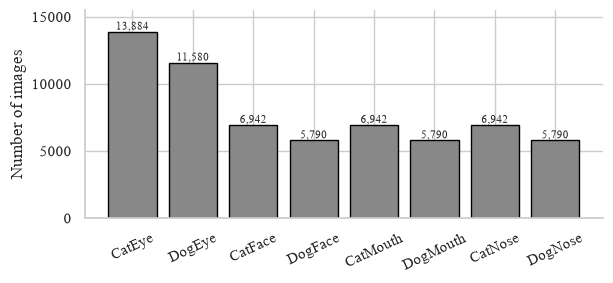

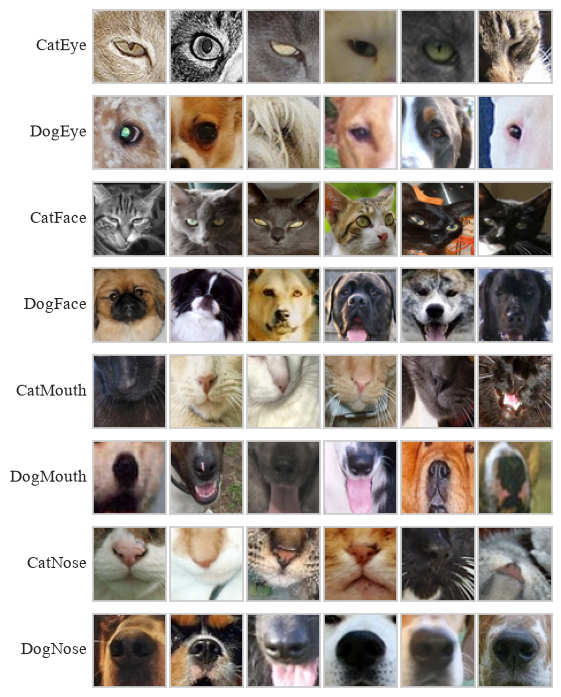

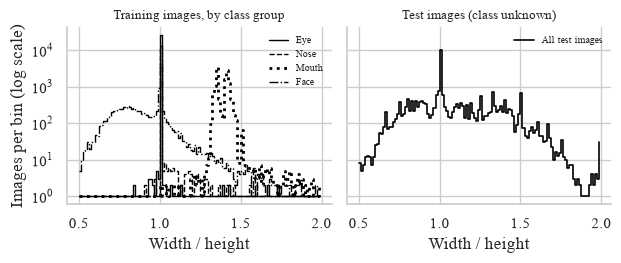

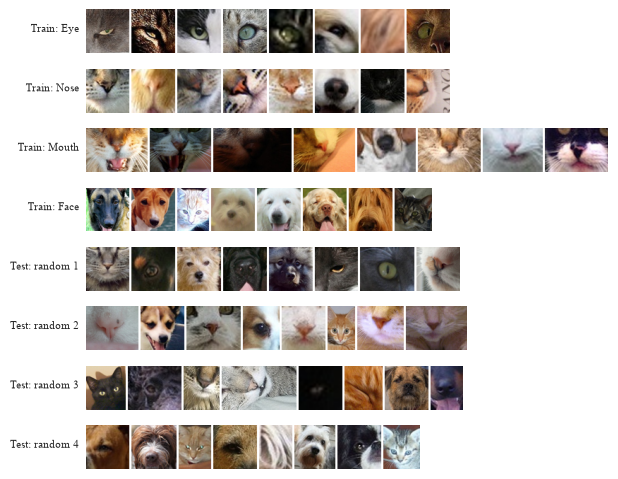

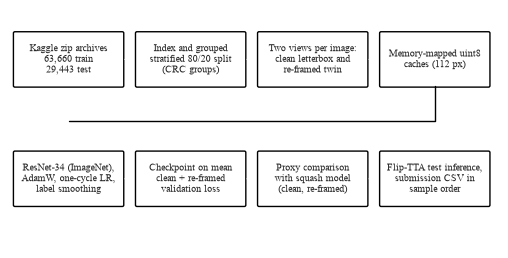

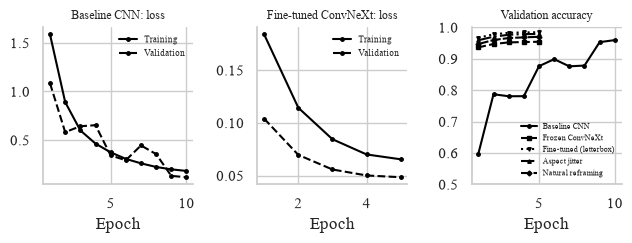

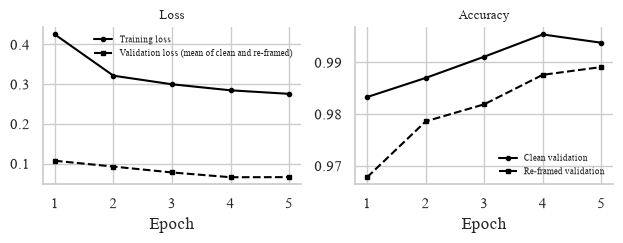

              precision    recall  f1-score   support

      CatEye     0.9975    0.9957    0.9966      2777
      DogEye     0.9931    0.9974    0.9953      2316
     CatFace     1.0000    0.9993    0.9996      1389
     DogFace     1.0000    1.0000    1.0000      1158
    CatMouth     0.9957    0.9950    0.9953      1388
    DogMouth     0.9966    0.9983    0.9974      1158
     CatNose     0.9928    0.9906    0.9917      1388
     DogNose     0.9983    0.9965    0.9974      1158

    accuracy                         0.9965     12732
   macro avg     0.9967    0.9966    0.9967     12732
weighted avg     0.9965    0.9965    0.9965     12732

accuracy 0.9965 (Table 7 reports 0.9965)
          CatEye  DogEye  CatFace  DogFace  CatMouth  DogMouth  CatNose  DogNose
CatEye      2765       9        0        0         0         0        3        0
DogEye         6    2310        0        0         0         0        0        0
CatFace        1       0     1388        0         0         0   

In [42]:
# COMMIT 14: Report Figures and Report Tables
# Implementation Scope:
# - Rebuild every figure used in the report from the zip archives, the saved training histories and the Commit 12 log.
# - Print the numbers behind Table 2 (image size and shape) and Table 3 (frame shape by class).
# - Print the per-class validation results of the final re-framed ResNet-34 (Table 8).
# - Write the PNG files to report_figures/.

# importing the one extra plotting class needed for the pipeline diagram
from matplotlib.patches import FancyBboxPatch

# using a serif font in every figure so they match the report text
plt.rcParams.update({"font.family": "serif", "font.serif": ["Times New Roman", "Liberation Serif", "DejaVu Serif"], "font.size": 9})
FIG_DIR = Path("report_figures")
FIG_DIR.mkdir(exist_ok=True)
HISTORY_DIR = CONFIG["history_dir"]
CLASSES = CONFIG["classes"]
# class groups used by the aspect-ratio histogram and the montage
GROUPS = {"Eye": ("CatEye", "DogEye"), "Nose": ("CatNose", "DogNose"), "Mouth": ("CatMouth", "DogMouth"), "Face": ("CatFace", "DogFace")}
archives = {}


# reading the width and height of every image from its file header, without decoding the pixels
def scan(zip_paths):
    rows = []
    for zip_path in zip_paths:
        archives[zip_path] = zipfile.ZipFile(zip_path)
        for info in archives[zip_path].infolist():
            name = PurePosixPath(info.filename)
            if info.is_dir() or name.parts[0] == "__MACOSX" or name.name.startswith("._") or name.suffix.lower() not in CONFIG["image_extensions"]:
                continue
            with archives[zip_path].open(info) as handle:
                width, height = Image.open(handle).size
            rows.append((name.stem, zip_path, info.filename, width, height))
    frame = pd.DataFrame(rows, columns=["id", "zip", "member", "w", "h"])
    frame["ratio"] = frame.w / frame.h
    return frame


# decoding one scanned image back to RGB
def read_image(row):
    return Image.open(io.BytesIO(archives[row.zip].read(row.member))).convert("RGB")


train = scan(CONFIG["train_archives"]).merge(
    pd.read_csv(CONFIG["labels_csv"], dtype={"image_id": str}), left_on="id", right_on="image_id")
test = scan(CONFIG["test_archives"])
# the scan must see exactly the images the pipeline used, otherwise the report numbers would not match the models
assert len(train) == len(labels) and len(test) == len(test_archive), "scan does not match the pipeline archives"

# printing the numbers behind Table 2 and Table 3 of the report
def shape_summary(frame):
    short_side = frame[["w", "h"]].min(axis=1)
    return pd.Series({
        "images": len(frame),
        "median width": frame.w.median(), "median height": frame.h.median(),
        "width min": frame.w.min(), "width max": frame.w.max(),
        "short side below 224": (short_side < 224).mean(),
        "non-square share": ((frame.ratio < 0.95) | (frame.ratio > 1.05)).mean(),
        "exactly square": int((frame.w == frame.h).sum()),
        "exactly square share": (frame.w == frame.h).mean(),
    })


print(pd.DataFrame({"train": shape_summary(train), "test": shape_summary(test)}).round(4).to_string())
print(f"test images expected to be exactly square if shaped like training: {len(test) * (train.w == train.h).mean():,.0f}")
print(train.groupby("class").ratio.agg(
    non_square=lambda r: ((r < 0.95) | (r > 1.05)).mean(), median_ratio="median").reindex(CLASSES).round(3).to_string())

# Figure 1: number of training images per class
counts = train["class"].value_counts().reindex(CLASSES)
fig, ax = plt.subplots(figsize=(6.2, 2.9))
bars = ax.bar(CLASSES, counts.values, color="#888888", edgecolor="black")
for bar, value in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 150, f"{value:,}", ha="center", fontsize=8)
ax.set_ylabel("Number of images")
ax.set_ylim(0, 15500)
ax.spines[["top", "right"]].set_visible(False)
plt.xticks(rotation=25)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig1_classes.png", dpi=200)
plt.show()

# Figure 2: six random training images per class (fixed seeds, so the same images appear on every run)
rng = np.random.default_rng(3)
fig, axes = plt.subplots(8, 6, figsize=(5.6, 7.0))
for r, name in enumerate(CLASSES):
    for c, row in enumerate(train[train["class"] == name].sample(6, random_state=int(rng.integers(1_000_000))).itertuples()):
        axes[r, c].imshow(read_image(row).resize((64, 64)))
        axes[r, c].set_xticks([])
        axes[r, c].set_yticks([])
    axes[r, 0].set_ylabel(name, rotation=0, ha="right", va="center")
plt.subplots_adjust(left=0.17, right=0.99, top=0.99, bottom=0.01, wspace=0.05, hspace=0.05)
plt.savefig(FIG_DIR / "fig2_samples.png", dpi=200)
plt.show()

# Figure 3 (the histogram): width-to-height ratio of training images by class group, beside the test images
bins = np.linspace(0.5, 2.0, 121)
styles = {"Eye": "-", "Nose": "--", "Mouth": ":", "Face": "-."}
fig, axes = plt.subplots(1, 2, figsize=(6.3, 2.7), sharey=True)
for group, names in GROUPS.items():
    counts_in_bin, _ = np.histogram(train[train["class"].isin(names)].ratio, bins)
    # adding 1 to every bin so empty bins stay visible on the log axis
    axes[0].step(bins[:-1], counts_in_bin + 1, where="post", color="black", ls=styles[group], lw=2 if group == "Mouth" else 1, label=group)
axes[1].step(bins[:-1], np.histogram(test.ratio, bins)[0] + 1, where="post", color="black", lw=1.2, label="All test images")
for axis, title in zip(axes, ("Training images, by class group", "Test images (class unknown)")):
    axis.set_yscale("log")
    axis.set_xlabel("Width / height")
    axis.set_title(title, fontsize=9)
    axis.legend(fontsize=7, frameon=False)
    axis.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Images per bin (log scale)")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig3_aspect.png", dpi=200)
plt.show()


# joining images side by side at one height, keeping each image's own aspect ratio
def strip(images, height=62):
    resized = [im.resize((max(1, int(im.width * height / im.height)), height)) for im in images]
    canvas = Image.new("RGB", (sum(im.width for im in resized) + 3 * (len(resized) - 1), height), "white")
    x = 0
    for im in resized:
        canvas.paste(im, (x, 0))
        x += im.width + 3
    return canvas


# Figure 4 (the montage): one strip per training class group (top four) and four strips of random test images
rows = [(f"Train: {g}", strip([read_image(r) for r in train[train["class"].isin(n)].sample(8, random_state=11).itertuples()]))
        for g, n in GROUPS.items()]
rows += [(f"Test: random {k + 1}", strip([read_image(r) for r in test.sample(8, random_state=20 + k).itertuples()])) for k in range(4)]
widest = max(img.width for _, img in rows)
fig = plt.figure(figsize=(6.3, 4.9))
for k, (label, img) in enumerate(rows):
    axis = fig.add_axes([0.16, 1 - (k + 1) / len(rows) * 0.97 - 0.01, 0.83 * img.width / widest, 0.97 / len(rows) * 0.93])
    axis.imshow(img)
    axis.axis("off")
    fig.text(0.15, 1 - (k + 0.5) / len(rows) * 0.97 - 0.01, label, ha="right", va="center", fontsize=8)
plt.savefig(FIG_DIR / "fig4_montage.png", dpi=200)
plt.show()

# Figure 5: the final pipeline drawn as two rows of boxes (a drawn diagram, not a data plot)
fig, axis = plt.subplots(figsize=(6.3, 3.1))
axis.axis("off")
axis.set_xlim(0, 10)
axis.set_ylim(0, 5)
top = ["Kaggle zip archives\n63,660 train\n29,443 test", "Index and grouped\nstratified 80/20 split\n(CRC groups)",
       "Two views per image:\nclean letterbox and\nre-framed twin", "Memory-mapped uint8\ncaches (112 px)"]
bottom = ["ResNet-34 (ImageNet),\nAdamW, one-cycle LR,\nlabel smoothing", "Checkpoint on mean\nclean + re-framed\nvalidation loss",
          "Proxy comparison\nwith squash model\n(clean, re-framed)", "Flip-TTA test inference,\nsubmission CSV in\nsample order"]
xs = [0.1, 2.6, 5.1, 7.6]
for y, labels_row in ((3.4, top), (0.9, bottom)):
    for x, text in zip(xs, labels_row):
        axis.add_patch(FancyBboxPatch((x, y), 2.2, 1.1, boxstyle="round,pad=0.03", fc="white", ec="black", lw=1))
        axis.text(x + 1.1, y + 0.55, text, ha="center", va="center", fontsize=7.2)
    for a, b in zip(xs[:-1], xs[1:]):
        axis.annotate("", xy=(b, y + 0.55), xytext=(a + 2.2, y + 0.55), arrowprops=dict(arrowstyle="->", lw=1))
axis.plot([8.7, 8.7, 1.2], [3.4, 2.65, 2.65], color="black", lw=1)
axis.annotate("", xy=(1.2, 2.0), xytext=(1.2, 2.65), arrowprops=dict(arrowstyle="->", lw=1))
plt.savefig(FIG_DIR / "fig5_pipeline.png", dpi=200, bbox_inches="tight")
plt.show()

# Figure 6: learning curves of the first-phase runs, read from the saved history files
runs = {name: pd.read_csv(HISTORY_DIR / f"{file}_history.csv") for name, file in (
    ("Baseline CNN", "baseline_cnn"), ("Frozen ConvNeXt", "transfer_convnext_tiny"), ("Fine-tuned (letterbox)", "finetune_convnext_tiny"),
    ("Aspect jitter", "finetune_convnext_tiny_aspect"), ("Natural reframing", "finetune_convnext_tiny_reframe"))}
baseline, tuned = runs["Baseline CNN"], runs["Fine-tuned (letterbox)"]
fig, axes = plt.subplots(1, 3, figsize=(6.4, 2.5))
for column, style, label in (("train_loss", "-", "Training"), ("val_loss", "--", "Validation")):
    axes[0].plot(range(1, len(baseline) + 1), baseline[column], style, color="black", marker="o", ms=2.5, label=label)
    axes[1].plot(range(1, len(tuned) + 1), tuned[column], style, color="black", marker="o", ms=2.5, label=label)
axes[0].set_title("Baseline CNN: loss", fontsize=8.5)
axes[1].set_title("Fine-tuned ConvNeXt: loss", fontsize=8.5)
for (name, history), marker, style in zip(runs.items(), "osv^D", ("-", "--", ":", "-.", (0, (5, 1)))):
    axes[2].plot(range(1, len(history) + 1), history.val_acc, ls=style, color="black", marker=marker, ms=2.5, label=name)
axes[2].set_title("Validation accuracy", fontsize=8.5)
axes[2].set_ylim(0.5, 1.0)
for axis in axes:
    axis.set_xlabel("Epoch")
    axis.spines[["top", "right"]].set_visible(False)
axes[0].legend(fontsize=6.5, frameon=False)
axes[1].legend(fontsize=6.5, frameon=False)
axes[2].legend(fontsize=5.5, frameon=False, loc="lower right")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig6_curves.png", dpi=200)
plt.show()

# Figure 7: the Commit 12 epoch log typed in by hand, because that run printed its metrics but did not save a history file
epochs = [1, 2, 3, 4, 5]
log = {"train loss": [0.4252, 0.3213, 0.2997, 0.2845, 0.2756], "val loss": [0.1070, 0.0923, 0.0775, 0.0655, 0.0657],
       "clean acc": [0.9833, 0.9870, 0.9911, 0.9954, 0.9938], "re-framed acc": [0.9678, 0.9786, 0.9819, 0.9876, 0.9891]}
fig, axes = plt.subplots(1, 2, figsize=(6.3, 2.5))
axes[0].plot(epochs, log["train loss"], "-", color="black", marker="o", ms=3, label="Training loss")
axes[0].plot(epochs, log["val loss"], "--", color="black", marker="s", ms=3, label="Validation loss (mean of clean and re-framed)")
axes[1].plot(epochs, log["clean acc"], "-", color="black", marker="o", ms=3, label="Clean validation")
axes[1].plot(epochs, log["re-framed acc"], "--", color="black", marker="s", ms=3, label="Re-framed validation")
axes[0].set_title("Loss", fontsize=9)
axes[1].set_title("Accuracy", fontsize=9)
for axis in axes:
    axis.set_xlabel("Epoch")
    axis.set_xticks(epochs)
    axis.legend(fontsize=6.5, frameon=False)
    axis.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig7_final.png", dpi=200)
plt.show()

# Table 8: per-class results of the final re-framed ResNet-34 on the clean validation images (same split as Commit 12)
train_entries, train_ids_rf, crcs = rf_index(CONFIG["train_archives"], RF["limit"])
label_of = labels.set_index("image_id")["class"]
y_all = np.array([rf_CLASS_IDX[label_of[i]] for i in train_ids_rf])
_, val_idx_rf = next(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RF["seed"]).split(train_ids_rf, y_all, groups=crcs))
rf_model = rf_build_model(False).to(device)
rf_model.load_state_dict(torch.load(RF["checkpoint"], map_location=device))
rf_clean_val = rf_open_maps({}, "r")[("val", "lb_clean")]
y_true_rf = y_all[val_idx_rf]
y_pred_rf = rf_predict(rf_model, rf_clean_val, device).argmax(1)
print(classification_report(y_true_rf, y_pred_rf, target_names=rf_CLASSES, digits=4))
print(f"accuracy {(y_true_rf == y_pred_rf).mean():.4f} (Table 7 reports 0.9965)")
print(pd.DataFrame(confusion_matrix(y_true_rf, y_pred_rf), index=rf_CLASSES, columns=rf_CLASSES).to_string())
del rf_model
